# Домашнее задание 2. Вариант CV: детекция на YOLO

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и версия (1.5) · 1.2 архитектура (2.5) | 4 |
| 2. Данные | 2.1 свой датасет (1.5) · 2.2 формат разметки (2.5) | 4 |
| 3. Бейзлайн | 3.1 до дообучения (2) | 2 |
| 4. Дообучение | 4.1 обучение (3) · 4.2 метрики (3) | 6 |
| 5. Анализ | 5.1 разбор ошибок (2) · 5.2 абляция (1) · 5.3 выводы (1) | 4 |
| 6*. Бонусы | 6.1 доразметка (1.5) · 6.2 RT-DETR (1) · 6.3 сдвиг домена (1) · 6.4 ONNX и скорость (1) · 6.5 пороги (1) | до +4 |
| итого | | 20 + 4 |


**Сведения о сдаче:**

**Ответ:**
- Устройство: Kaggle, GPU Tesla T4, ultralytics 8.4.216, `FAST_MODE = False`.
- Модель: `yolo26n.pt` (AGPL-3.0).
- Бонусы: 6.2, 6.3, 6.4, 6.5.
- Датасет: SeaDronesSee Object Detection v2, зеркало https://huggingface.co/datasets/dronefreak/SeaDronesSee, подвыборка 2400 / 400 / 1000 кадров (train / valid / test).

Прогон на Kaggle занимает больше часа (но меньше двух), ну и какая-то весомая доля уходит на бонусы, основная часть меньше. Если пытаться жёстко уложиться в час, то наверное выйдет что-то совсем игрушечное на датасете из 1.5 картинок, а хотелось всё-таки чего-то более полноценного.

In [1]:
import importlib.util, subprocess, sys

REQUIREMENTS = {
    'ultralytics': 'ultralytics>=8.4.0,<8.5',
    'huggingface_hub': 'huggingface_hub',
}

for module_name, requirement in REQUIREMENTS.items():
    if importlib.util.find_spec(module_name) is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', requirement], check=True)

import csv
import functools
import hashlib
import io
import json
import math
import os
import random
import shutil
import time
import xml.etree.ElementTree as ET

from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import requests
import yaml

from huggingface_hub import HfApi
from matplotlib.patches import Rectangle
from PIL import Image, ImageFilter
from scipy import ndimage

import torch
import torchvision
from torchvision.ops import box_iou
import ultralytics
from ultralytics import RTDETR, YOLO

plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 12
try:
    from matplotlib_inline.backend_inline import set_matplotlib_formats
    set_matplotlib_formats('jpeg')
except ImportError:
    pass

DEVICE = 0 if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
DEVICE_NAME = torch.cuda.get_device_name(0) if torch.cuda.is_available() else str(DEVICE)
print(f'ultralytics {ultralytics.__version__}, torch {torch.__version__}, device: {DEVICE_NAME}')

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
ultralytics 8.4.216, torch 2.11.0+cu130, device: Tesla T4


In [2]:
FAST_MODE = False
BONUS_TASKS = {'6.2', '6.3', '6.4', '6.5'}

SEED = 0
DATA_ROOT = Path('data')
RUNS = Path('runs_hw2')
IMGSZ = 320 if FAST_MODE else 960
EPOCHS = 2 if FAST_MODE else 40
BATCH = 8 if FAST_MODE else 16

N_TRAIN_FAST = 64
WORKERS = 0 if os.name == 'nt' else 2
RUN_TIMES = {}


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed()

Общие функции: рисование боксов и mAP50 для своих предсказаний. Предсказания и разметка одной картинки - словари `dict(boxes=(n, 4) xyxy в пикселях, labels=(n,), scores=(n,))`, у разметки нет `scores`.

In [ ]:
COLORS = [
    '#2F3E55',
    '#B8616B',
    '#5E8C8A',
    '#D4A35F',
    '#8F81AB',
    '#4F6D8C',
    '#8E3B2E',
    '#7FA7C2',
    '#D4B45F',
    '#B07C8C',
]


def draw_boxes(ax, image, boxes, labels, names, scores=None, color=None, linestyle='-', title=None):
    if image is not None:
        ax.imshow(image)

    for k, (box, label) in enumerate(zip(np.asarray(boxes).reshape(-1, 4), np.asarray(labels).reshape(-1))):
        x1, y1, x2, y2 = box
        c = color or COLORS[int(label) % 10]
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=c, linewidth=1.5, linestyle=linestyle))
        text = names[int(label)] + ('' if scores is None else f' {scores[k]:.2f}')
        ax.text(x1, y1, text, color='white', fontsize=7, clip_on=True, bbox=dict(facecolor=c, alpha=0.7, pad=1, edgecolor='none'))
    ax.set_axis_off()

    if title:
        ax.set_title(title, fontsize=10)


def evaluate_map50(preds, gts, n_classes, iou_thr=0.5):
    aps = []
    for c in range(n_classes):
        hits, n_gt = [], 0

        for p, g in zip(preds, gts):
            gb = torch.as_tensor(np.asarray(g['boxes'])[np.asarray(g['labels']) == c], dtype=torch.float32).reshape(-1, 4)
            keep = np.asarray(p['labels']) == c
            pb = torch.as_tensor(np.asarray(p['boxes'])[keep], dtype=torch.float32).reshape(-1, 4)
            ps = np.asarray(p['scores'])[keep]
            n_gt += len(gb)
            ious = box_iou(pb, gb).numpy() if len(pb) and len(gb) else np.zeros((len(pb), len(gb)))
            used = np.zeros(len(gb), dtype=bool)

            for i in np.argsort(-ps, kind='stable'):
                j = int(ious[i].argmax()) if len(gb) else -1
                hit = j >= 0 and ious[i, j] >= iou_thr and not used[j]
                if hit:
                    used[j] = True
                hits.append((ps[i], hit))

        if n_gt == 0:
            aps.append(float('nan'))
            continue

        hits.sort(key=lambda t: -t[0])
        tp = np.cumsum([h for _, h in hits]) if hits else np.zeros(0)
        fp = np.cumsum([not h for _, h in hits]) if hits else np.zeros(0)
        recall = np.concatenate([[0], tp / n_gt, [1]])
        precision = np.concatenate([[1], tp / np.maximum(tp + fp, 1), [0]])
        precision = np.maximum.accumulate(precision[::-1])[::-1]
        aps.append(float(np.sum(np.diff(recall) * precision[1:])))
    
    return float(np.nanmean(aps)), aps


def predict_records(model, recs, conf=0.001, batch=16, **kw):
    out = []
    for i in range(0, len(recs), batch):
        paths = [str(r['image']) for r in recs[i:i + batch]]
        for res in model.predict(paths, conf=conf, imgsz=IMGSZ, device=DEVICE, verbose=False, **kw):
            b = res.boxes.cpu()
            out.append(dict(boxes=b.xyxy.numpy(), scores=b.conf.numpy(), labels=b.cls.numpy().astype(np.int64)))
    return out


def pick_frame_indices(recs, count, key=None):
    common_size = Counter((record['width'], record['height']) for record in recs).most_common(1)[0][0]
    indices = [index for index, record in enumerate(recs) if (record['width'], record['height']) == common_size]
    
    if key is not None:
        indices = sorted(indices, key=lambda index: key(recs[index]))

    chosen, used_blocks = [], set()
    for index in indices:
        block = int(Path(recs[index]['image']).stem) // 100
        if block not in used_blocks:
            chosen.append(index)
            used_blocks.add(block)

    return chosen[:count]


def frame_grid(n_rows, n_columns, aspect=9 / 16, cell_width=7):
    fig, axes = plt.subplots(
        n_rows,
        n_columns,
        figsize=(cell_width * n_columns, (cell_width * aspect + 0.5) * n_rows),
        constrained_layout=True,
    )
    return fig, np.atleast_1d(axes).ravel()

---
# 1. Модель

## 1.1 Модель и версия (1.5 балла)

Скачайте предобученный детектор ultralytics и зафиксируйте, что именно скачали: версию библиотеки и файл весов. На семинаре был `yolo26n.pt` (обучен на COCO, 80 классов); можно взять другой размер того же семейства (`yolo26s.pt`, `yolo26m.pt`) или YOLO11, если обоснуете. Веса в релизе могут перезалить, а дефолты обучения меняются между версиями ultralytics, поэтому запишите sha256 файла весов.

Заполните `MODEL_INFO`: версия ultralytics, имя файла весов, sha256, размер файла в МБ, число параметров, число классов COCO и задержка на одной картинке `IMGSZ x IMGSZ` в мс (после прогрева, среднее по 10+ запускам). Параметры считайте до первого `predict`: при предсказании ultralytics сливает Conv и BatchNorm прямо в объекте модели.

**Вопрос.** Почему этот размер модели под ваш датасет и бюджет (T4, около часа)? Сравните с соседним размером по параметрам, mAP на COCO и скорости из [таблицы в документации](https://docs.ultralytics.com/models/yolo26/). Какая лицензия у кода и весов ultralytics и что она требует?

In [ ]:
WEIGHTS = 'yolo26n.pt'
model_coco = YOLO(WEIGHTS)
weights_path = Path(WEIGHTS) if Path(WEIGHTS).exists() else Path(model_coco.ckpt_path)


def measure_latency(model, imgsz, runs=20, warmup=5, device=DEVICE, **kwargs):
    image = np.zeros((imgsz, imgsz, 3), dtype=np.uint8)
    for _ in range(warmup):
        model.predict(image, imgsz=imgsz, device=device, verbose=False, **kwargs)

    if torch.cuda.is_available():
        torch.cuda.synchronize()
    start = time.perf_counter()
    for _ in range(runs):
        model.predict(image, imgsz=imgsz, device=device, verbose=False, **kwargs)
    if torch.cuda.is_available():
        torch.cuda.synchronize()

    return (time.perf_counter() - start) / runs * 1000


n_params = sum(parameter.numel() for parameter in model_coco.model.parameters())

MODEL_INFO = dict(
    ultralytics=ultralytics.__version__,
    weights=weights_path.name,
    sha256=hashlib.sha256(weights_path.read_bytes()).hexdigest(),
    size_mb=weights_path.stat().st_size / 2 ** 20,
    params=n_params,
    n_classes_coco=len(model_coco.names),
    latency_ms=measure_latency(model_coco, IMGSZ),
)

In [5]:
assert 'MODEL_INFO' in globals(), 'сначала заполните MODEL_INFO в ячейке выше'
assert set(MODEL_INFO) >= {'ultralytics', 'weights', 'sha256', 'size_mb', 'params', 'n_classes_coco', 'latency_ms'}
assert len(MODEL_INFO['sha256']) == 64 and MODEL_INFO['params'] > 0 and MODEL_INFO['latency_ms'] > 0
MODEL_INFO

{'ultralytics': '8.4.216',
 'weights': 'yolo26n.pt',
 'sha256': '9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef',
 'size_mb': 5.287602424621582,
 'params': 2572280,
 'n_classes_coco': 80,
 'latency_ms': 14.891045849999784}

**Ответ:** Взята `yolo26n`: на этом датасете качество определяет разрешение, а не размер модели (пловец занимает около 1% ширины кадра), и n при 960 обучается за полчаса на T4. По таблице документации s даёт +7.7 п.п. на COCO (48.6 против 40.9 mAP50-95), но имеет в 4 раза больше параметров (9.5 M против 2.4 M) и вдвое медленнее на CPU (87 против 39 мс). Код и веса ultralytics выходят под AGPL-3.0: их можно использовать и менять, но производную работу нужно открывать под той же лицензией (в том числе при сетевом использовании).

## 1.2 Архитектура (2.5 балла)

Детектор ultralytics - это `DetectionModel`, внутри `det_model.model` - `nn.Sequential` слоев в порядке из yaml-конфига: сначала backbone (`det_model.yaml['backbone']`), потом neck, последний слой - голова `Detect`.

1. Напишите `params_by_block(det_model)`: число параметров в backbone, neck и head
2. Напишите `head_inputs_and_output(det_model, imgsz)`: прогоните dummy-вход `1 x 3 x imgsz x imgsz` в eval-режиме и верните формы карт признаков, которые приходят в `Detect` (forward hook), и выход модели
3. Напечатайте формы выхода (выход - вложенные tuple / dict, функция `shapes` ниже поможет)

**Вопрос.** Распишите блоки: что делает backbone, что делает neck (какие масштабы объединяет), что предсказывает head в каждой точке карты признаков. Почему детектор называют anchor-free? Откуда число 8400 при входе 640? Что значат две ветки выхода `one2many` и `one2one` и почему YOLO26 обходится без NMS? Какая доля параметров в каждом блоке?

In [ ]:
def params_by_block(det_model):
    # -> dict(backbone=..., neck=..., head=...): число параметров в каждом блоке
    layers = det_model.model
    n_backbone = len(det_model.yaml['backbone'])

    def count(modules):
        return sum(parameter.numel() for module in modules for parameter in module.parameters())

    return dict(
        backbone=count(layers[:n_backbone]),
        neck=count(layers[n_backbone:-1]),
        head=count(layers[-1:]),
    )


def head_inputs_and_output(det_model, imgsz=640):
    # -> (список форм карт признаков на входе Detect, выход модели на нулевом входе 1 x 3 x imgsz x imgsz)
    captured = {}

    def save_input_shapes(module, inputs):
        captured['shapes'] = [tuple(feature.shape) for feature in inputs[0]]

    handle = det_model.model[-1].register_forward_pre_hook(save_input_shapes)
    det_model.eval()
    try:
        with torch.no_grad():
            output = det_model(torch.zeros(1, 3, imgsz, imgsz))
    finally:
        handle.remove()

    return captured['shapes'], output


def shapes(obj):
    if isinstance(obj, torch.Tensor):
        return tuple(obj.shape)
    if isinstance(obj, (list, tuple)):
        return [shapes(o) for o in obj]
    if isinstance(obj, dict):
        return {k: shapes(v) for k, v in obj.items()}
    return type(obj).__name__

In [7]:
arch = YOLO(WEIGHTS).model   # свежая копия: у model_coco после predict Conv и BN уже слиты
blocks = params_by_block(arch)
total = sum(p.numel() for p in arch.parameters())
assert set(blocks) == {'backbone', 'neck', 'head'}
assert sum(blocks.values()) == total, (blocks, total)
assert all(v > 0 for v in blocks.values())
assert blocks['head'] == sum(p.numel() for p in arch.model[-1].parameters())

feat_shapes, out = head_inputs_and_output(arch, 640)
assert len(feat_shapes) == 3 and [s[-1] for s in feat_shapes] == [80, 40, 20], feat_shapes   # страйды 8, 16, 32
print({k: f'{v:,} ({v / total:.0%})' for k, v in blocks.items()}, f'total {total:,}')
print('на входе Detect:', feat_shapes)

{'backbone': '1,365,472 (53%)', 'neck': '897,152 (35%)', 'head': '309,656 (12%)'} total 2,572,280
на входе Detect: [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]


In [8]:
n_backbone = len(arch.yaml['backbone'])

print('layer  block     type          from        params')
for index, layer in enumerate(arch.model):
    block = 'backbone' if index < n_backbone else ('head' if index == len(arch.model) - 1 else 'neck')
    n_layer_params = sum(parameter.numel() for parameter in layer.parameters())
    print(f'{index:>5}  {block:<8}  {layer.type.split(".")[-1]:<12}  {str(layer.f):<10}  {n_layer_params:>9,}')

print()
print('output structure:')
print(shapes(out))

n_points = sum(shape[-2] * shape[-1] for shape in feat_shapes)
print()
print('points per feature map:', ' + '.join(f'{shape[-2]}x{shape[-1]}' for shape in feat_shapes), '=', n_points)

layer  block     type          from        params
    0  backbone  Conv          -1                464
    1  backbone  Conv          -1              4,672
    2  backbone  C3k2          -1              6,640
    3  backbone  Conv          -1             36,992
    4  backbone  C3k2          -1             26,080
    5  backbone  Conv          -1            147,712
    6  backbone  C3k2          -1             87,040
    7  backbone  Conv          -1            295,424
    8  backbone  C3k2          -1            346,112
    9  backbone  SPPF          -1            164,608
   10  backbone  C2PSA         -1            249,728
   11  neck      Upsample      -1                  0
   12  neck      Concat        [-1, 6]             0
   13  neck      C3k2          -1            119,808
   14  neck      Upsample      -1                  0
   15  neck      Concat        [-1, 4]             0
   16  neck      C3k2          -1             34,304
   17  neck      Conv          -1             36,

**Ответ:** Backbone сжимает картинку в 32 раза и вытаскивает признаки на нескольких уровнях. Neck склеивает глубокие признаки с более подробными, и на выходе получаются три карты: подробная для мелких объектов и самая грубая для крупных. Head в каждой точке этих карт предсказывает бокс и классы. Доли параметров: backbone 53%, neck 35%, head 12%.

Детектор называют anchor-free, потому что в нём нет заранее заданных якорей: бокс считается от точки карты. Число 8400 — это сумма точек трёх карт при входе 640 (80^2 + 40^2 + 20^2). Ветка `one2many` выдаёт много кандидатов на объект и требует NMS, а `one2one` обучена давать по одному боксу на объект, поэтому YOLO26 может обойтись без NMS.

---
# 2. Данные

## 2.1 Свой датасет (1.5 балла)

Найдите датасет детекции, лучше такой, где классов нет в COCO или COCO-модель работает плохо. Где искать:

- [Roboflow Universe](https://universe.roboflow.com) - тысячи датасетов детекции с экспортом в YOLO / COCO / VOC, нужен бесплатный аккаунт. API-ключ в ноутбук не кладите: скачайте zip руками или читайте ключ из переменной окружения
- [Kaggle Datasets](https://www.kaggle.com/datasets?search=object+detection) - нужен аккаунт и `kaggle.json`, в Kaggle-ноутбуке датасет подключается кнопкой Add Input
- [Hugging Face Hub](https://huggingface.co/datasets?task_categories=task_categories:object-detection) - фильтр object-detection, многие датасеты скачиваются без ключей
- [Open Images V7](https://storage.googleapis.com/openimages/web/index.html) - 600 классов, отдельные классы удобно выгружать через FiftyOne
- GitHub-репозитории статей и учебные датасеты в формате VOC XML / COCO JSON

Требования: открытая лицензия (CC BY, CC0, MIT, Apache и т.п., укажите какая), не PennFudan и не coco8 / coco128, от ~150 картинок, и чтобы обучение с `FAST_MODE = False` укладывалось примерно в час на T4. Если в датасете нет val, сделайте сплит с фиксированным seed. Если картинок очень много, возьмите подмножество и напишите, как выбирали.

Контракт для следующих задач: `records[split]` - список словарей `dict(image=путь, width=..., height=..., boxes=np.ndarray (n, 4) float в пикселях xyxy, labels=np.ndarray (n,) int)`, `CLASSES` - список имен классов, `DATASET_NAME` - название, ссылка и лицензия одной строкой. Боксы с нулевой площадью и выходящие за картинку почистите (обрежьте) и посчитайте, сколько таких было.

Посчитайте статистику: объекты на класс по сплитам, объекты на картинку, размеры боксов (в пикселях или в долях картинки, гистограмма или scatter по классам).

**Вопрос.** Опишите источник, лицензию, классы, размер и сплиты. Что видно из статистики: дисбаланс классов, мелкие объекты, плотные сцены? Какие проблемы разметки заметили?

In [ ]:
REPO_ID = 'dronefreak/SeaDronesSee'
REVISION = 'deb1f872ffe7efa4b7ee3a672562d16b6dc0ca5c'
BASE_URL = f'https://huggingface.co/datasets/{REPO_ID}/resolve/{REVISION}/'
MAX_SIDE = 1280
BLOCK_SIZE = 100
DOWNLOAD_THREADS = 8
SPLIT_SEED = 97
SPLIT_SIZES = dict(train=64, val=32, test=32) if FAST_MODE else dict(train=2400, val=400, test=1000)
RAW_ROOT = DATA_ROOT / 'raw'
IMAGE_ROOT = DATA_ROOT / 'resized'


def fetch_file(path, retries=8):
    headers = {}
    if os.environ.get('HF_TOKEN'):
        headers['Authorization'] = f'Bearer {os.environ["HF_TOKEN"]}'

    for attempt in range(retries):
        try:
            response = requests.get(BASE_URL + path, headers=headers, timeout=120)
        except requests.RequestException:
            time.sleep(5 * (attempt + 1))
            continue

        if response.status_code == 429:
            time.sleep(min(float(response.headers.get('Retry-After', 10 * (attempt + 1))), 120))
            continue

        response.raise_for_status()
        return response.content

    raise RuntimeError(f'could not download {path}')


def prepare_item(task):
    split, official_split, shard, image_id = task
    label_path = RAW_ROOT / 'labels' / split / f'{image_id}.txt'
    image_path = IMAGE_ROOT / split / f'{image_id}.jpg'

    if not label_path.exists():
        label_path.parent.mkdir(parents=True, exist_ok=True)
        label_path.write_bytes(fetch_file(f'data/labels/{official_split}/{shard}/{image_id}.txt'))

    if not image_path.exists():
        image_path.parent.mkdir(parents=True, exist_ok=True)
        image = Image.open(io.BytesIO(fetch_file(f'data/images/{official_split}/{shard}/{image_id}.jpg')))
        image.draft('RGB', (MAX_SIDE, MAX_SIDE))
        image = image.convert('RGB')
        scale = MAX_SIDE / max(image.size)
        if scale < 1:
            image = image.resize((round(image.width * scale), round(image.height * scale)), Image.LANCZOS)

        temporary_path = image_path.with_suffix('.tmp')
        image.save(temporary_path, format='JPEG', quality=92)
        temporary_path.replace(image_path)

    with Image.open(image_path) as image:
        width, height = image.size

    rows = np.array(label_path.read_text().split(), dtype=np.float64).reshape(-1, 5)
    labels = rows[:, 0].astype(np.int64)
    center = rows[:, 1:3] * [width, height]
    size = rows[:, 3:5] * [width, height]
    boxes = np.concatenate([center - size / 2, center + size / 2], axis=1)

    limits = np.array([width, height, width, height])
    n_outside = int(((boxes < -1e-3) | (boxes > limits + 1e-3)).any(axis=1).sum())
    boxes = np.clip(boxes, 0, limits)
    keep = (boxes[:, 2] > boxes[:, 0]) & (boxes[:, 3] > boxes[:, 1])

    record = dict(
        image=image_path,
        width=width,
        height=height,
        boxes=boxes[keep].astype(np.float32),
        labels=labels[keep],
        raw_label=label_path,
    )
    return record, n_outside, int((~keep).sum())


# какие кадры есть в репозитории
repo_files = HfApi().list_repo_files(REPO_ID, repo_type='dataset', revision=REVISION)
shard_of = {'train': {}, 'val': {}}
for path in repo_files:
    parts = path.split('/')
    if parts[:2] == ['data', 'labels'] and parts[-1].endswith('.txt'):
        shard_of[parts[2]][int(Path(parts[-1]).stem)] = parts[3]

# train / valid делится из официального train целыми блоками id, чтобы соседние кадры одного видео не раскидались
# официальный val (другие съемки) целиком под test
split_rng = np.random.default_rng(SPLIT_SEED)
train_ids = np.array(sorted(shard_of['train']))
block_ids = np.unique(train_ids // BLOCK_SIZE)
split_rng.shuffle(block_ids)

valid_blocks, valid_candidates = [], []
for block in block_ids:
    if len(valid_candidates) >= SPLIT_SIZES['val']:
        break
    valid_blocks.append(block)
    valid_candidates += train_ids[train_ids // BLOCK_SIZE == block].tolist()

valid_ids = np.sort(split_rng.choice(valid_candidates, SPLIT_SIZES['val'], replace=False))
train_pool = train_ids[~np.isin(train_ids // BLOCK_SIZE, valid_blocks)]

rng = np.random.default_rng(SEED)
selected = dict(
    train=('train', np.sort(rng.choice(train_pool, SPLIT_SIZES['train'], replace=False))),
    val=('train', valid_ids),
    test=('val', np.sort(rng.choice(sorted(shard_of['val']), SPLIT_SIZES['test'], replace=False))),
)

records = {}
cleaning = Counter()
start = time.perf_counter()

for split, (official_split, ids) in selected.items():
    tasks = [(split, official_split, shard_of[official_split][int(image_id)], int(image_id)) for image_id in ids]
    with ThreadPoolExecutor(DOWNLOAD_THREADS) as executor:
        results = list(executor.map(prepare_item, tasks))

    records[split] = [record for record, _, _ in results]
    cleaning['outside_image'] += sum(n_outside for _, n_outside, _ in results)
    cleaning['dropped_zero_area'] += sum(n_dropped for _, _, n_dropped in results)
    print(f'{split}: {len(records[split])} images from official {official_split}')

RUN_TIMES['download'] = time.perf_counter() - start
print(f'boxes clipped to the image: {cleaning["outside_image"]}, dropped as zero-area: {cleaning["dropped_zero_area"]}')
print(f'download and resize: {RUN_TIMES["download"]:.0f} s')

with open(RAW_ROOT / 'data.yaml', 'w') as file:
    file.write(fetch_file('data/data.yaml').decode())
class_names = yaml.safe_load((RAW_ROOT / 'data.yaml').read_text())['names']
CLASSES = [class_names[index] for index in range(len(class_names))]

DATASET_NAME = (
    'SeaDronesSee Object Detection v2 (mirror dronefreak/SeaDronesSee, revision deb1f87), '
    'https://huggingface.co/datasets/dronefreak/SeaDronesSee, CC0 1.0'
)

train: 2400 images from official train
val: 400 images from official train
test: 1000 images from official val
boxes clipped to the image: 0, dropped as zero-area: 0
download and resize: 709 s


In [10]:
assert all(n in globals() for n in ('records', 'CLASSES', 'DATASET_NAME')), 'сначала заполните records, CLASSES, DATASET_NAME'
assert {'train', 'val'} <= set(records) and len(CLASSES) > 0 and isinstance(DATASET_NAME, str)
for split, recs in records.items():
    for r in recs:
        assert Path(r['image']).exists() and r['boxes'].shape == (len(r['labels']), 4), r['image']
        assert (r['boxes'][:, 2] > r['boxes'][:, 0]).all() and (r['boxes'][:, 3] > r['boxes'][:, 1]).all(), r['image']
        assert ((r['labels'] >= 0) & (r['labels'] < len(CLASSES))).all(), r['image']
{split: len(recs) for split, recs in records.items()}

{'train': 2400, 'val': 400, 'test': 1000}

class                       train      val     test
swimmer                     10000     2146     4110
boat                         3507      245     1467
jetski                        641      178      212
life_saving_appliances        196      179      222
buoy                         1203      183      383

train: 2400 images, objects per image: mean 6.5, median 6, max 16, image sizes (top 3): [((1280, 720), 1996), ((1280, 852), 218), ((852, 1280), 74)]
val: 400 images, objects per image: mean 7.3, median 9, max 14, image sizes (top 3): [((1280, 720), 342), ((1280, 852), 49), ((852, 1280), 9)]
test: 1000 images, objects per image: mean 6.4, median 7, max 16, image sizes (top 3): [((1280, 720), 843), ((1280, 852), 92), ((852, 1280), 25)]

train box size, fraction of image width (median w, median h, share of boxes with max side < 1%):
  swimmer                  0.0109  0.0096  39%
  boat                     0.0301  0.0224  5%
  jetski                   0.0206  0.0141  11%
  life_savi

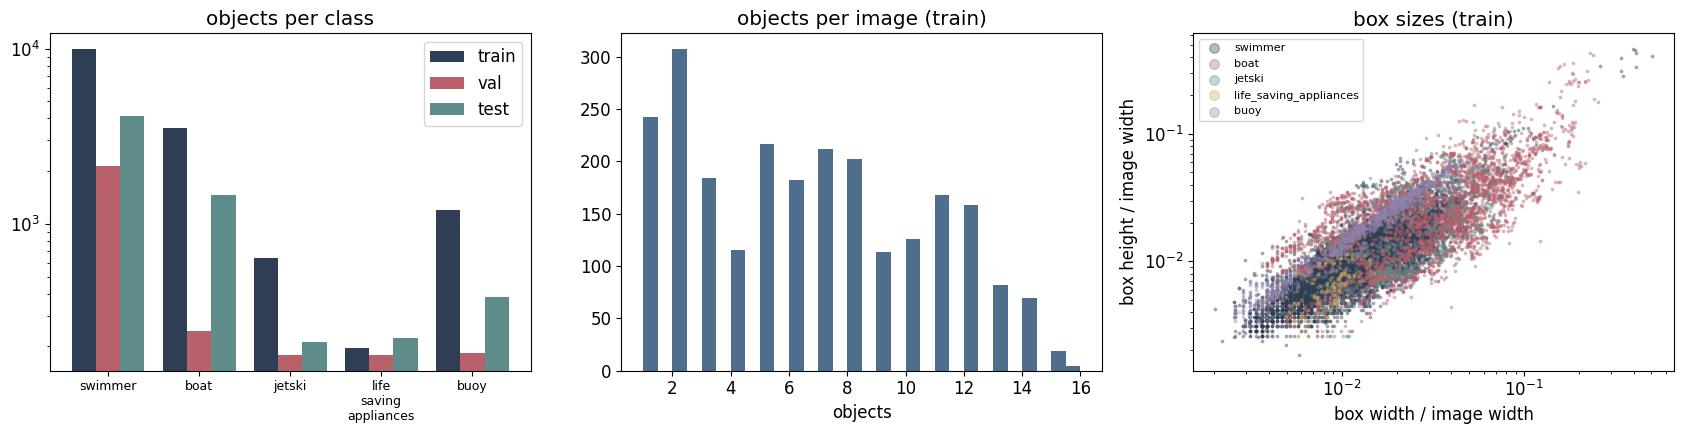

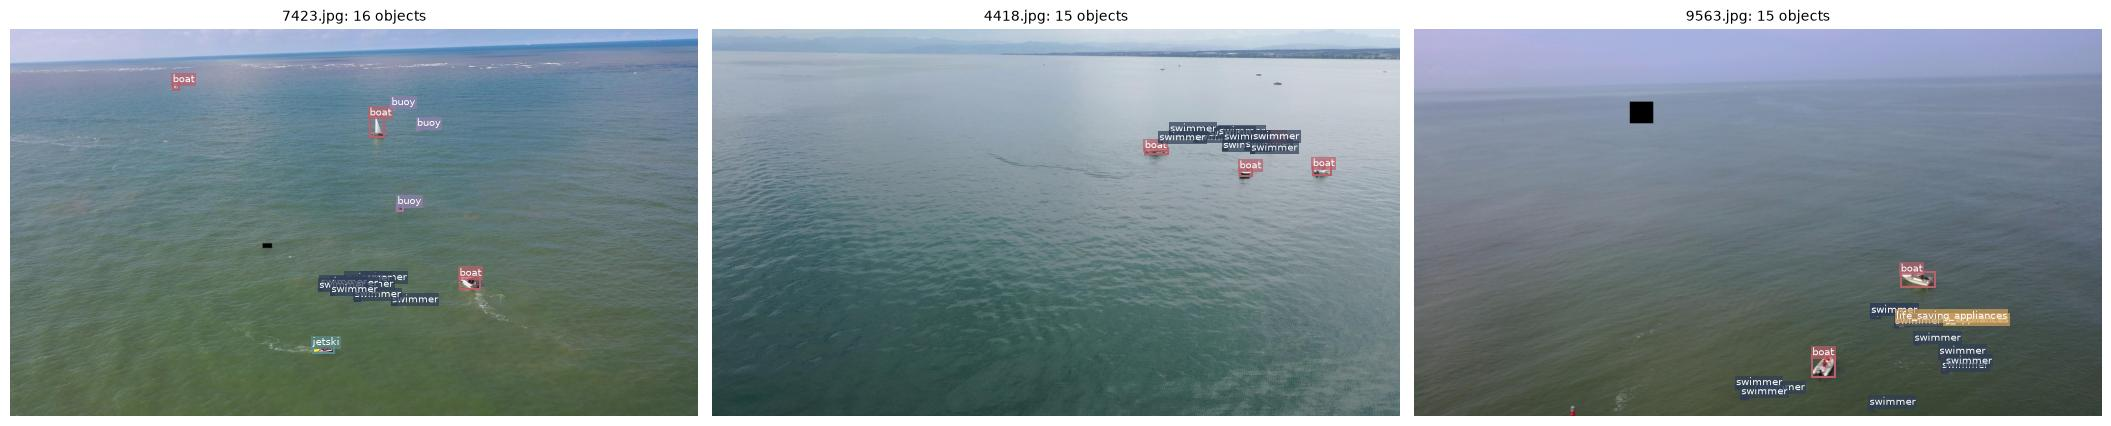

In [ ]:
split_counts = {
    split: np.bincount(np.concatenate([record['labels'] for record in recs]), minlength=len(CLASSES))
    for split, recs in records.items()
}

print(f'{"class":<24}' + ''.join(f'{split:>9}' for split in records))
for index, name in enumerate(CLASSES):
    print(f'{name:<24}' + ''.join(f'{split_counts[split][index]:>9}' for split in records))

print()
for split, recs in records.items():
    per_image = np.array([len(record['labels']) for record in recs])
    sizes = Counter((record['width'], record['height']) for record in recs)
    print(
        f'{split}: {len(recs)} images, objects per image: mean {per_image.mean():.1f}, '
        f'median {np.median(per_image):.0f}, max {per_image.max()}, '
        f'image sizes (top 3): {sizes.most_common(3)}'
    )

# размеры боксов в долях ширины картинки, тк масштабы сцен разные
all_boxes = np.concatenate([record['boxes'] / record['width'] for record in records['train']])
all_labels = np.concatenate([record['labels'] for record in records['train']])
box_widths = all_boxes[:, 2] - all_boxes[:, 0]
box_heights = all_boxes[:, 3] - all_boxes[:, 1]

print()
print('train box size, fraction of image width (median w, median h, share of boxes with max side < 1%):')

for index, name in enumerate(CLASSES):
    selected_boxes = all_labels == index
    if selected_boxes.any():
        small_share = (np.maximum(box_widths, box_heights)[selected_boxes] < 0.01).mean()
        print(
            f'  {name:<24} {np.median(box_widths[selected_boxes]):.4f}  '
            f'{np.median(box_heights[selected_boxes]):.4f}  {small_share:.0%}'
        )

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

bar_width = 0.8 / len(records)
for position, (split, counts) in enumerate(split_counts.items()):
    axes[0].bar(np.arange(len(CLASSES)) + position * bar_width, counts, bar_width, label=split, color=COLORS[position])

axes[0].set_xticks(np.arange(len(CLASSES)) + bar_width, [name.replace('_', '\n') for name in CLASSES], fontsize=9)
axes[0].set_yscale('log')
axes[0].set_title('objects per class')
axes[0].legend()

per_image_train = [len(record['labels']) for record in records['train']]
axes[1].hist(per_image_train, bins=30, color=COLORS[5])
axes[1].set_title('objects per image (train)')
axes[1].set_xlabel('objects')

for index, name in enumerate(CLASSES):
    selected_boxes = all_labels == index
    axes[2].scatter(box_widths[selected_boxes], box_heights[selected_boxes], s=3, alpha=0.35, color=COLORS[index], label=name)

axes[2].set_xscale('log')
axes[2].set_yscale('log')
axes[2].set_xlabel('box width / image width')
axes[2].set_ylabel('box height / image width')
axes[2].set_title('box sizes (train)')
axes[2].legend(markerscale=4, fontsize=8)

plt.tight_layout()
plt.show()

# примеры кадров с разметкой
fig, axes = frame_grid(1, 3)
for ax, index in zip(axes, pick_frame_indices(records['train'], 3, key=lambda record: -len(record['labels']))):
    record = records['train'][index]
    draw_boxes(
        ax,
        Image.open(record['image']),
        record['boxes'],
        record['labels'],
        CLASSES,
        title=f'{Path(record["image"]).name}: {len(record["labels"])} objects',
    )
plt.show()

**Ответ:** SeaDronesSee: кадры с дронов над водой для поиска людей. Датасет открытый (CC0), классов пять: пловцы, лодки, гидроциклы, спасательные средства и буи. Подвыборка устроена так: 2400 кадров в train, 400 в valid и 1000 в test (в test ушёл официальный val, где съемки другие). Valid собран блоками соседних кадров, чтобы почти одинаковые кадры не попали и в train, и в valid. Кадры уменьшены до 1280 по длинной стороне.

Из статистики видно, что классы сильно несбалансированы (пловцов в разы больше остальных, спасательных средств совсем мало), объекты очень мелкие (обычно около процента ширины кадра), а пловцы часто стоят группами, и рамки у них перекрываются. Valid по составу классов заметно отличается от train и test, поэтому метрики на них напрямую сравнивать нельзя. Из проблем разметки: на части кадров закрашены чёрным целые участки, а у совсем крошечных объектов граница бокса неоднозначна.

## 2.2 Формат разметки (2.5 балла)

ultralytics ждет YOLO-формат: на каждую картинку `images/<split>/<имя>.jpg` есть `labels/<split>/<имя>.txt`, в нем строка на объект `class cx cy w h`, координаты центра и размеры нормированы на ширину и высоту картинки, плюс `data.yaml` с путями и именами классов.

1. Напишите `to_yolo` и `from_yolo` (6 знаков после запятой, пустая разметка - пустой текст)
2. Напишите `export_split`: копирует картинки и пишет txt-разметку сплита в `YOLO_ROOT`
3. Прочитайте разметку обратно из txt-файлов (`from_yolo`) и нарисуйте боксы на 3-4 картинках: так ловятся перепутанные оси и ненормированные координаты

Если ваш датасет уже в YOLO-формате, сделайте обратную конвертацию YOLO -> COCO JSON (`to_coco` / `from_coco` своим кодом) и проверку туда-обратно на всем датасете, `to_yolo` / `from_yolo` все равно реализуйте: на них открытые тесты.

**Вопрос.** Что проверяет тест туда-обратно и чего он не ловит? Какие ошибки конвертации вы бы заметили только на картинке?

In [ ]:
def to_yolo(boxes, labels, width, height):
    # boxes: (n, 4) xyxy в пикселях, labels: (n,) -> текст, строка 'class cx cy w h' на объект, координаты в [0, 1]
    boxes = np.asarray(boxes, dtype=np.float64).reshape(-1, 4)
    labels = np.asarray(labels).reshape(-1)

    lines = []
    for (x1, y1, x2, y2), label in zip(boxes, labels):
        center_x = (x1 + x2) / 2 / width
        center_y = (y1 + y2) / 2 / height
        box_width = (x2 - x1) / width
        box_height = (y2 - y1) / height
        lines.append(f'{int(label)} {center_x:.6f} {center_y:.6f} {box_width:.6f} {box_height:.6f}')

    return '\n'.join(lines) + '\n' if lines else ''


def from_yolo(text, width, height):
    # -> boxes (n, 4) float32 xyxy в пикселях, labels (n,) int64; пустой текст -> формы (0, 4) и (0,)
    rows = [line.split() for line in text.strip().splitlines() if line.strip()]
    if not rows:
        return np.zeros((0, 4), dtype=np.float32), np.zeros(0, dtype=np.int64)

    values = np.array([[float(token) for token in row[:5]] for row in rows], dtype=np.float64)
    labels = values[:, 0].astype(np.int64)
    center_x, center_y = values[:, 1] * width, values[:, 2] * height
    box_width, box_height = values[:, 3] * width, values[:, 4] * height
    boxes = np.stack(
        [
            center_x - box_width / 2,
            center_y - box_height / 2,
            center_x + box_width / 2,
            center_y + box_height / 2,
        ],
        axis=1,
    )
    return boxes.astype(np.float32), labels

In [13]:
t = to_yolo(np.array([[10, 20, 110, 70]]), np.array([2]), 200, 100)
assert t.split() == ['2', '0.300000', '0.450000', '0.500000', '0.500000'], t
assert to_yolo(np.zeros((0, 4)), np.zeros(0, dtype=np.int64), 640, 480).strip() == ''
b, l = from_yolo('', 640, 480)
assert b.shape == (0, 4) and l.shape == (0,)
b, l = from_yolo('1 0.5 0.5 0.25 0.5\n0 0.1 0.2 0.1 0.2\n', 400, 200)
assert np.allclose(b, [[150, 50, 250, 150], [20, 20, 60, 60]], atol=1e-3) and l.tolist() == [1, 0], (b, l)

rng = np.random.default_rng(0)
for _ in range(100):
    W, H = rng.integers(32, 2000, size=2)
    n = int(rng.integers(1, 30))
    xy = rng.uniform(0, 1, (n, 2)) * [W, H]
    boxes = np.concatenate([xy, np.minimum(xy + rng.uniform(1, 0.5 * min(W, H), (n, 2)), [W, H])], axis=1)
    labels = rng.integers(0, 5, n)
    b, l = from_yolo(to_yolo(boxes, labels, W, H), W, H)
    assert np.allclose(b, boxes, atol=1e-5 * max(W, H) + 1e-3) and (l == labels).all()
print('to_yolo / from_yolo: ok')

to_yolo / from_yolo: ok


In [14]:
YOLO_ROOT = DATA_ROOT / 'yolo'


def export_split(recs, split):
    # картинки -> YOLO_ROOT/images/<split>/, разметка -> YOLO_ROOT/labels/<split>/<имя>.txt
    image_dir = YOLO_ROOT / 'images' / split
    label_dir = YOLO_ROOT / 'labels' / split
    image_dir.mkdir(parents=True, exist_ok=True)
    label_dir.mkdir(parents=True, exist_ok=True)

    for record in recs:
        image_path = Path(record['image'])
        shutil.copy2(image_path, image_dir / image_path.name)
        text = to_yolo(record['boxes'], record['labels'], record['width'], record['height'])
        (label_dir / f'{image_path.stem}.txt').write_text(text)


order = np.random.default_rng(SEED).permutation(len(records['train']))
train_recs = [records['train'][i] for i in order[:N_TRAIN_FAST]] if FAST_MODE else records['train']
shutil.rmtree(YOLO_ROOT, ignore_errors=True)   # старые файлы и *.cache ultralytics от прошлых прогонов
splits = {'train': train_recs, **{s: r for s, r in records.items() if s != 'train'}}
for split, recs in splits.items():
    export_split(recs, split)
DATA_YAML = YOLO_ROOT / 'data.yaml'
DATA_YAML.write_text(f'path: {YOLO_ROOT.resolve().as_posix()}\n'
                     + ''.join(f'{s}: images/{s}\n' for s in splits)
                     + 'names:\n' + ''.join(f'  {i}: {n}\n' for i, n in enumerate(CLASSES)))
for split, recs in splits.items():
    assert len(list((YOLO_ROOT / 'labels' / split).glob('*.txt'))) == len(recs), split
FINAL_SPLIT = 'test' if 'test' in records else 'val'   # на нем считаются бейзлайн (3.1) и финальные метрики (4.2)
print(DATA_YAML.read_text())

path: /kaggle/working/data/yolo
train: images/train
val: images/val
test: images/test
names:
  0: swimmer
  1: boat
  2: jetski
  3: life_saving_appliances
  4: buoy



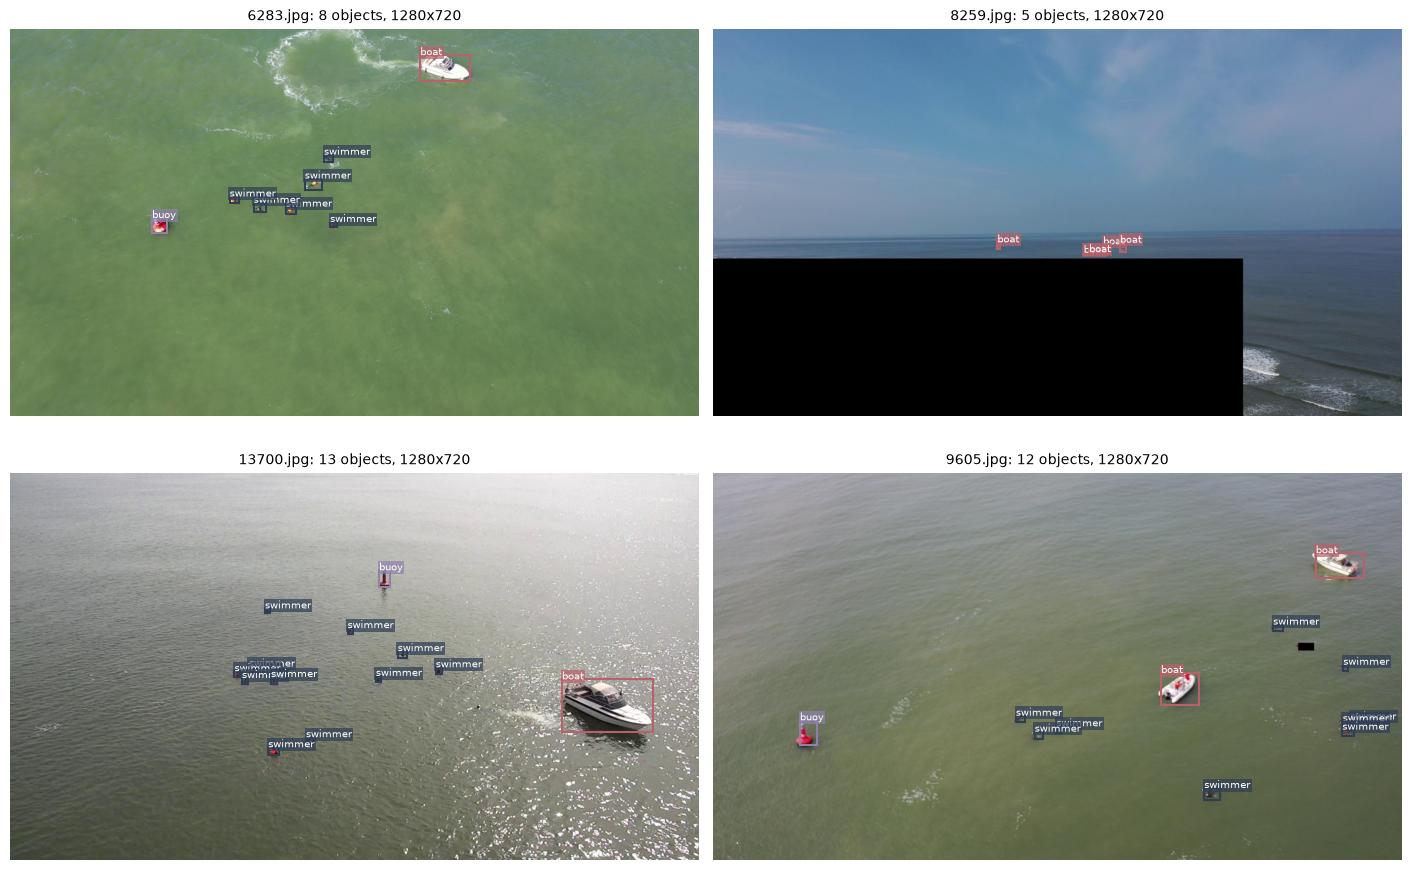

YOLO -> COCO -> YOLO round trip on all 3800 images: max box difference 3.05e-05 px
exported labels vs raw dataset labels: 3800 images identical (max difference 6.41e-04 px), 0 images with cleaned boxes


In [ ]:
def to_coco(recs, classes):
    # записи датасета -> COCO JSON: bbox = [x, y, w, h] в пикселях, category_id начинается с 1
    images, annotations = [], []
    for image_id, record in enumerate(recs):
        images.append(dict(
            id=image_id,
            file_name=Path(record['image']).name,
            width=record['width'],
            height=record['height'],
        ))
        for (x1, y1, x2, y2), label in zip(record['boxes'], record['labels']):
            annotations.append(dict(
                id=len(annotations),
                image_id=image_id,
                category_id=int(label) + 1,
                bbox=[float(x1), float(y1), float(x2 - x1), float(y2 - y1)],
                area=float((x2 - x1) * (y2 - y1)),
                iscrowd=0,
            ))

    categories = [dict(id=index + 1, name=name) for index, name in enumerate(classes)]
    return dict(images=images, annotations=annotations, categories=categories)


def from_coco(coco):
    # COCO JSON -> dict(file_name -> (boxes (n, 4) xyxy float32, labels (n,) int64))
    category_index = {category['id']: index for index, category in enumerate(sorted(coco['categories'], key=lambda c: c['id']))}
    names = {image['id']: image['file_name'] for image in coco['images']}
    grouped = {name: ([], []) for name in names.values()}

    for annotation in coco['annotations']:
        x, y, width, height = annotation['bbox']
        boxes, labels = grouped[names[annotation['image_id']]]
        boxes.append([x, y, x + width, y + height])
        labels.append(category_index[annotation['category_id']])

    return {
        name: (np.array(boxes, dtype=np.float32).reshape(-1, 4), np.array(labels, dtype=np.int64))
        for name, (boxes, labels) in grouped.items()
    }


rng = np.random.default_rng(SEED)
same_size = [splits['train'][index] for index in pick_frame_indices(splits['train'], len(splits['train']))]
dense = [record for record in same_size if len(record['labels']) >= 5]
chosen = [dense[index] for index in rng.choice(len(dense), min(4, len(dense)), replace=False)]

fig, axes = frame_grid(2, 2)
for ax, record in zip(axes, chosen):
    label_text = (YOLO_ROOT / 'labels' / 'train' / f'{Path(record["image"]).stem}.txt').read_text()
    boxes, labels = from_yolo(label_text, record['width'], record['height'])
    draw_boxes(
        ax,
        Image.open(YOLO_ROOT / 'images' / 'train' / Path(record['image']).name),
        boxes,
        labels,
        CLASSES,
        title=f'{Path(record["image"]).name}: {len(labels)} objects, {record["width"]}x{record["height"]}',
    )
plt.show()

max_difference = 0.0
for split, recs in records.items():
    coco_path = DATA_ROOT / 'coco' / f'{split}.json'
    coco_path.parent.mkdir(parents=True, exist_ok=True)
    coco_path.write_text(json.dumps(to_coco(recs, CLASSES)))
    restored = from_coco(json.loads(coco_path.read_text()))

    for record in recs:
        boxes, labels = restored[Path(record['image']).name]
        assert boxes.shape == record['boxes'].shape and (labels == record['labels']).all(), record['image']
        if len(boxes):
            max_difference = max(max_difference, float(np.abs(boxes - record['boxes']).max()))

print(f'YOLO -> COCO -> YOLO round trip on all {sum(len(recs) for recs in records.values())} images: max box difference {max_difference:.2e} px')

n_equal, n_cleaned, max_difference = 0, 0, 0.0
for split, recs in splits.items():
    for record in recs:
        label_text = (YOLO_ROOT / 'labels' / split / f'{Path(record["image"]).stem}.txt').read_text()
        boxes, labels = from_yolo(label_text, record['width'], record['height'])
        raw_boxes, raw_labels = from_yolo(Path(record['raw_label']).read_text(), record['width'], record['height'])
        
        if len(raw_labels) != len(labels):
            n_cleaned += 1
            continue
        n_equal += 1

        if len(boxes):
            max_difference = max(max_difference, float(np.abs(boxes - raw_boxes).max()))

print(f'exported labels vs raw dataset labels: {n_equal} images identical (max difference {max_difference:.2e} px), '
      f'{n_cleaned} images with cleaned boxes')

**Ответ:** Тест туда-обратно проверяет только то, что две функции обратны друг другу. Но он не ловит ошибки, одинаковые в обе стороны: если в обеих функциях одинаково перепутать оси или нормировать не на ту сторону, цикл всё равно сойдётся. Также он пропустит сдвиг индексов классов или неправильно понятый формат источника. Такие ошибки видны только на картинке.

---
# 3. Бейзлайн

## 3.1 До дообучения (2 балла)

Нужна точка отсчета, без нее непонятно, сколько дало дообучение.

Все считается на `FINAL_SPLIT` (test, если он есть, иначе val) - на том же сплите, что и финальные метрики в 4.2.

1. Прогоните COCO-модель без дообучения. Если в COCO есть совпадающие классы (person, car, dog и т.п.), переназначьте их индексы на ваши и посчитайте mAP50 функцией `evaluate_map50`. Если совпадающих классов нет, покажите, что модель предсказывает на ваших картинках, и объясните, почему mAP равен нулю
2. Напишите тривиальный бейзлайн своим кодом без нейросетей: средние боксы класса из train на сетке, порог по цвету + связные компоненты (`scipy.ndimage.label`), скользящее окно с простым признаком и т.п. Параметры можно подбирать по train, но не по val. Оцените его через `evaluate_map50`. Бейзлайн не обязан быть хорошим

В первой ячейке задайте `coco_map50`, `BASELINE` соберется сам из него и результатов эвристики.

**Вопрос.** Почему у COCO-модели такое качество на ваших данных? На каких классах эвристика работает, а на каких нет и почему?

COCO classes predicted with conf >= 0.25: [('boat', 890), ('person', 761), ('kite', 674), ('bird', 82), ('surfboard', 45), ('snowboard', 4), ('frisbee', 3), ('tv', 3)]
COCO model without fine-tuning, mAP50 on test: 0.1694
  swimmer                  AP50 0.2366
  boat                     AP50 0.6103
  jetski                   AP50 0.0000
  life_saving_appliances   AP50 0.0000
  buoy                     AP50 0.0000


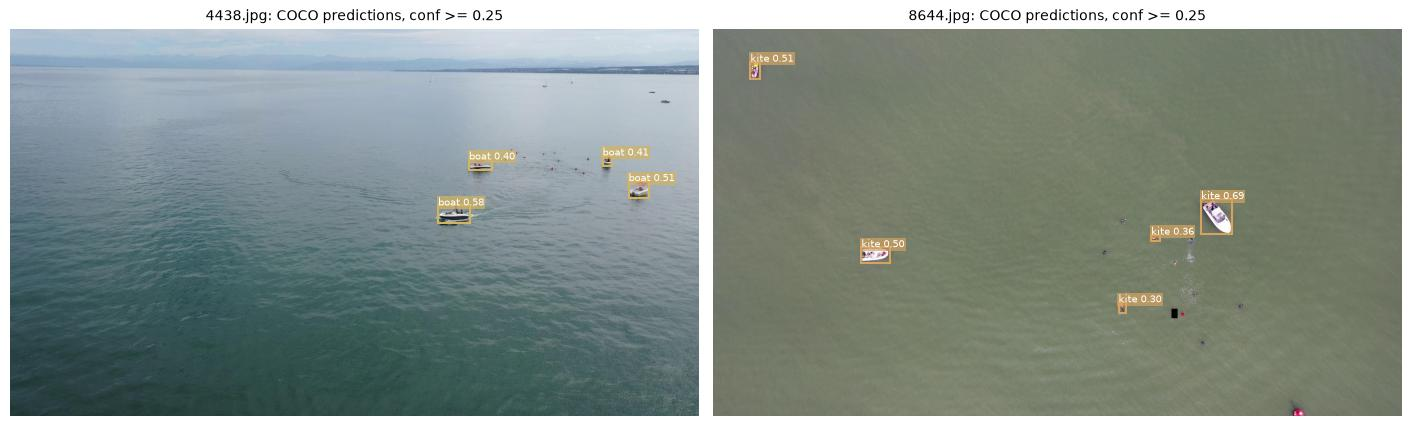

In [ ]:
# в COCO есть person и boat: person -> swimmer, boat -> boat
COCO_TO_OURS = {
    0: CLASSES.index('swimmer'),
    8: CLASSES.index('boat'),
}

start = time.perf_counter()
coco_preds = predict_records(model_coco, records[FINAL_SPLIT])
RUN_TIMES['coco_baseline'] = time.perf_counter() - start

coco_counts = Counter(
    model_coco.names[int(label)]
    for pred in coco_preds
    for label, score in zip(pred['labels'], pred['scores'])
    if score >= 0.25
)
print('COCO classes predicted with conf >= 0.25:', coco_counts.most_common(8))

mapped_preds = []
for pred in coco_preds:
    keep = np.isin(pred['labels'], list(COCO_TO_OURS))
    mapped_preds.append(dict(
        boxes=pred['boxes'][keep],
        scores=pred['scores'][keep],
        labels=np.array([COCO_TO_OURS[int(label)] for label in pred['labels'][keep]], dtype=np.int64),
    ))

coco_map50, coco_aps = evaluate_map50(mapped_preds, records[FINAL_SPLIT], len(CLASSES))
print(f'COCO model without fine-tuning, mAP50 on {FINAL_SPLIT}: {coco_map50:.4f}')
for name, ap in zip(CLASSES, coco_aps):
    print(f'  {name:<24} AP50 {ap:.4f}')

coco_names = [model_coco.names[index] for index in range(len(model_coco.names))]
fig, axes = frame_grid(1, 2)

for ax, index in zip(axes, pick_frame_indices(records[FINAL_SPLIT], 2, key=lambda record: -len(record['labels']))):
    record, pred = records[FINAL_SPLIT][index], coco_preds[index]
    keep = pred['scores'] >= 0.25
    draw_boxes(
        ax,
        Image.open(record['image']),
        pred['boxes'][keep],
        pred['labels'][keep],
        coco_names,
        scores=pred['scores'][keep],
        title=f'{Path(record["image"]).name}: COCO predictions, conf >= 0.25',
    )
plt.show()

In [ ]:
def anomaly_map(image_path):
    image = Image.open(image_path).convert('RGB').reduce(HEURISTIC['downscale'])
    pixels = np.asarray(image, dtype=np.float32)
    background = ndimage.gaussian_filter(pixels, sigma=(HEURISTIC['sigma'], HEURISTIC['sigma'], 0))
    return np.sqrt(((pixels - background) ** 2).sum(axis=2))


@functools.lru_cache(maxsize=512)
def cached_anomaly_map(image_path):
    return anomaly_map(image_path)


def heuristic_detect(image_path):
    # -> dict(boxes (n, 4) xyxy, scores (n,), labels (n,)) без нейросетей
    scale = HEURISTIC['downscale']
    pad = HEURISTIC['pad']
    anomaly = cached_anomaly_map(str(image_path))
    height, width = anomaly.shape[0] * scale, anomaly.shape[1] * scale

    components, count = ndimage.label(anomaly > HEURISTIC['threshold'], structure=np.ones((3, 3)))
    boxes, scores, labels = [], [], []
    if count == 0:
        return dict(boxes=np.zeros((0, 4)), scores=np.zeros(0), labels=np.zeros(0, dtype=np.int64))

    indices = np.arange(1, count + 1)
    peaks = ndimage.maximum(anomaly, components, index=indices)
    areas = ndimage.sum(np.ones_like(anomaly), components, index=indices)

    for (rows, columns), peak, area in zip(ndimage.find_objects(components), peaks, areas):
        if area < HEURISTIC['min_pixels']:
            continue

        box = np.array([
            max(columns.start * scale - pad, 0),
            max(rows.start * scale - pad, 0),
            min(columns.stop * scale + pad, width),
            min(rows.stop * scale + pad, height),
        ])
        if max(box[2] - box[0], box[3] - box[1]) > HEURISTIC['max_side']:
            continue

        size = np.log([box[2] - box[0], box[3] - box[1]])
        distance = np.sqrt(((HEURISTIC['prototypes'] - size) ** 2).sum(axis=1))
        weights = np.exp(-0.5 * (distance / HEURISTIC['size_sigma']) ** 2)
        for label, weight in enumerate(weights):
            if weight > 0.05:
                boxes.append(box)
                scores.append(float(peak) / 255 * weight)
                labels.append(label)

    return dict(
        boxes=np.array(boxes, dtype=np.float64).reshape(-1, 4),
        scores=np.array(scores, dtype=np.float64),
        labels=np.array(labels, dtype=np.int64),
    )

In [ ]:
# медианный размер (log w, log h) каждого класса в train
train_sizes = {index: [] for index in range(len(CLASSES))}

for record in records['train']:
    for box, label in zip(record['boxes'], record['labels']):
        train_sizes[int(label)].append([box[2] - box[0], box[3] - box[1]])

prototypes = np.array([
    np.log(np.median(sizes, axis=0)) if sizes else np.log([20.0, 20.0])
    for sizes in train_sizes.values()
])

HEURISTIC = dict(
    downscale=2,
    sigma=12,
    threshold=40.0,
    min_pixels=3,
    max_side=400,
    pad=2,
    size_sigma=0.8,
    prototypes=prototypes,
)

# подбор порога и минимальной площади по подвыборке train
tuning_rng = np.random.default_rng(SEED)
tuning_records = [records['train'][i] for i in tuning_rng.permutation(len(records['train']))[:100]]
grid = [(threshold, min_pixels) for threshold in (70.0, 100.0, 140.0, 200.0) for min_pixels in (4, 8, 16)]

best_score, best_params = -1.0, None
print('threshold  min_pixels  mAP50 (100 train images)')

for threshold, min_pixels in grid:
    HEURISTIC.update(threshold=threshold, min_pixels=min_pixels)
    tuning_preds = [heuristic_detect(record['image']) for record in tuning_records]
    score, _ = evaluate_map50(tuning_preds, tuning_records, len(CLASSES))
    print(f'{threshold:>9.0f}  {min_pixels:>10}  {score:.4f}')
    
    if score > best_score:
        best_score, best_params = score, (threshold, min_pixels)

HEURISTIC.update(threshold=best_params[0], min_pixels=best_params[1])
print(f'chosen: threshold {best_params[0]:.0f}, min_pixels {best_params[1]}')

threshold  min_pixels  mAP50 (100 train images)
       70           4  0.0116
       70           8  0.0122
       70          16  0.0130
      100           4  0.0228
      100           8  0.0232
      100          16  0.0237
      140           4  0.0219
      140           8  0.0219
      140          16  0.0223
      200           4  0.0036
      200           8  0.0036
      200          16  0.0036
chosen: threshold 100, min_pixels 16


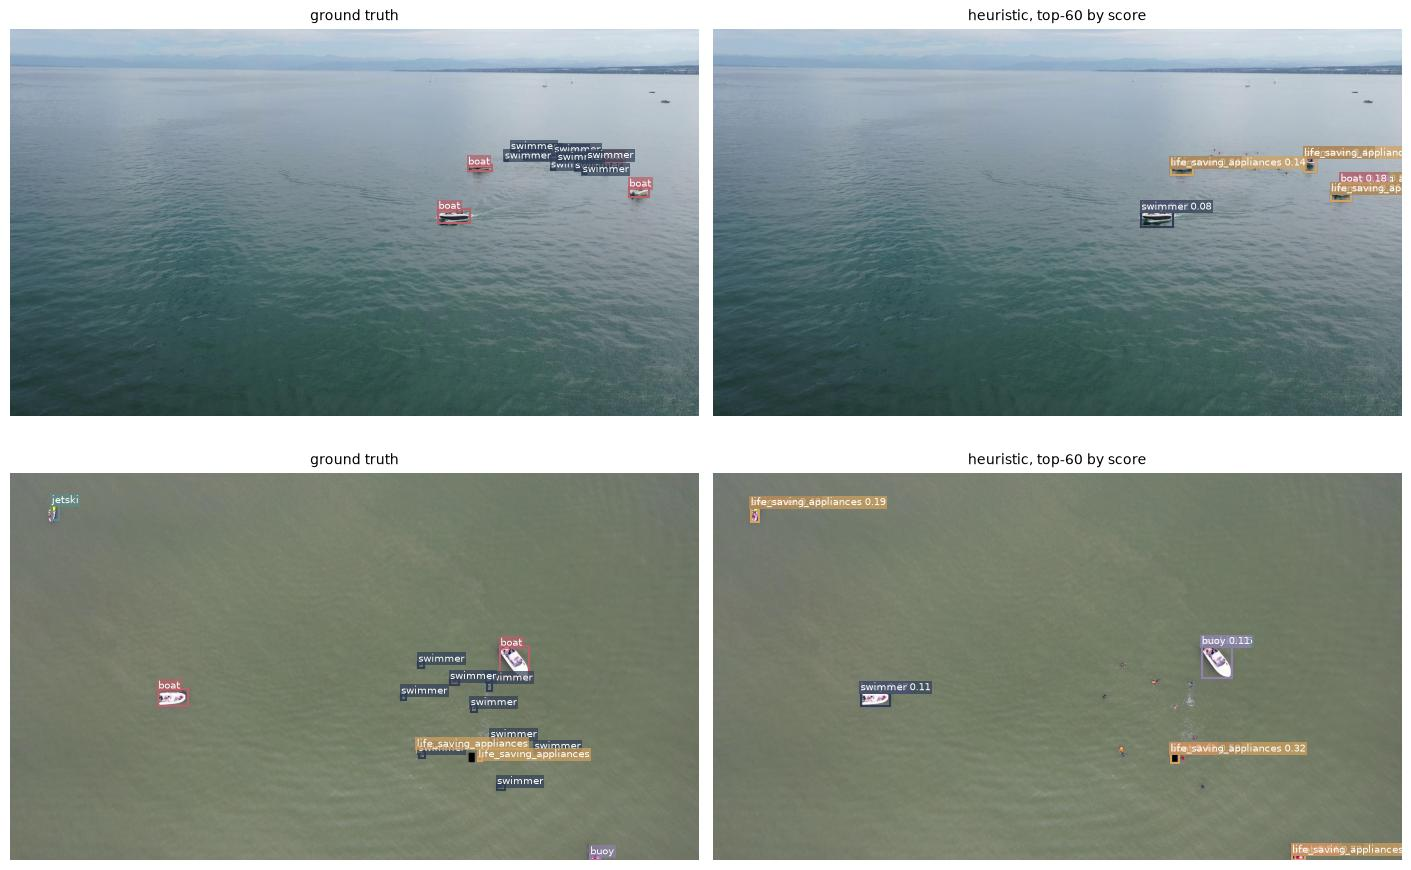

{'split': 'test',
 'coco_map50': 0.16938138747346737,
 'heuristic_map50': 0.021662809362653673,
 'heuristic_ap50_per_class': {'swimmer': 0.002502005071956704,
  'boat': 0.09634954496404192,
  'jetski': 0.0024707919087461083,
  'life_saving_appliances': 0.0006450262168140951,
  'buoy': 0.006346678651709526}}

In [ ]:
start = time.perf_counter()
heuristic_preds = [heuristic_detect(r['image']) for r in records[FINAL_SPLIT]]
heuristic_map50, heuristic_aps = evaluate_map50(heuristic_preds, records[FINAL_SPLIT], len(CLASSES))
RUN_TIMES['heuristic'] = time.perf_counter() - start
BASELINE = dict(split=FINAL_SPLIT, coco_map50=coco_map50, heuristic_map50=heuristic_map50,
                heuristic_ap50_per_class=dict(zip(CLASSES, heuristic_aps)))

fig, axes = frame_grid(2, 2)
for position, index in enumerate(pick_frame_indices(records[FINAL_SPLIT], 2, key=lambda record: -len(record['labels']))):
    record, pred = records[FINAL_SPLIT][index], heuristic_preds[index]
    row = axes[2 * position:2 * position + 2]
    image = Image.open(record['image'])
    draw_boxes(row[0], image, record['boxes'], record['labels'], CLASSES, title='ground truth')
    top = np.argsort(-pred['scores'])[:60]
    draw_boxes(
        row[1],
        image,
        pred['boxes'][top],
        pred['labels'][top],
        CLASSES,
        scores=pred['scores'][top],
        title='heuristic, top-60 by score',
    )
    
plt.show()

BASELINE

**Ответ:** COCO-модель работает плохо (mAP50 около 0.17): три класса из пяти (гидроцикл, спасательные средства, буи) в COCO просто нет. Лодки находятся заметно лучше (хотя она иногда называет их kite), а пловцов модель замечает лишь отчасти: съёмка сверху и объекты в десяток пикселей совсем не похожи на то, чему COCO учился. Эвристика (контраст с размытым фоном, порог, связные компоненты, класс по размеру) почти ничего не находит (mAP50 около 0.02) и хоть как-то работает только на лодках: они крупные, белые и хорошо видны на воде. Остальные классы она не отличает ни от бликов на волнах, ни друг от друга, потому что по размеру они почти одинаковы.

---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Дообучите модель из 1.1 на своем датасете. Гиперпараметры выберите осмысленно и объясните: число эпох, `imgsz` (размер объектов!), `batch` (память T4), оптимизатор и lr, аугментации (например, для микроскопии и снимков сверху уместен `flipud`, для текста и дорожных знаков - нет), `patience`. Список аргументов - в [документации](https://docs.ultralytics.com/modes/train/#train-settings). Валидацию во время обучения оставьте включенной: нужны val loss.

Заполните `TRAIN_ARGS`, обучение запускает готовая `train_yolo`. Нарисуйте кривые train и val loss по эпохам из `results.csv` (все компоненты loss, которые там есть) и mAP50 на val по эпохам. Напечатайте время обучения и устройство.

**Вопрос.** Почему такие гиперпараметры? Есть ли переобучение по кривым (train loss падает, val loss растет)? Хватило ли эпох?

In [ ]:
def train_yolo(name, weights=WEIGHTS, **args):
    # обертка над model.train: свой каталог прогона, замер времени; возвращает (модель, секунды, каталог прогона)
    model = YOLO(weights)
    start = time.perf_counter()
    model.train(data=str(DATA_YAML), device=DEVICE, workers=WORKERS, project=str(RUNS.resolve()), name=name,
                exist_ok=True, verbose=False, **args)
    return model, time.perf_counter() - start, Path(model.trainer.save_dir)


def read_results(run_dir):
    # results.csv ultralytics -> dict(колонка -> np.array по эпохам)
    with open(Path(run_dir) / 'results.csv', newline='') as f:
        rows = list(csv.DictReader(f))
    return {k.strip(): np.array([float(r[k]) for r in rows]) for k in rows[0]}

In [ ]:
TRAIN_ARGS = dict(
    epochs=EPOCHS,
    imgsz=IMGSZ,
    batch=BATCH,
    optimizer='AdamW',
    lr0=0.001,
    cos_lr=True,
    patience=15,
    flipud=0.5,
    fliplr=0.5,
    mosaic=1.0,
    close_mosaic=5,
    seed=SEED,
    plots=True,
    val=True,
)

model_ft, RUN_TIMES['train'], run_dir = train_yolo('finetune', **TRAIN_ARGS)
print(f'training: {RUN_TIMES["train"]:.0f} s on {DEVICE_NAME}, run directory {run_dir}')

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=5, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=data/yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=finetune, nbs=64, nms=None, opset=None, optimize=False, optimizer=Adam

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/40      6.48G       2.21      1.461   0.001925        186        960: 100% ━━━━━━━━━━━━ 150/150 3.3it/s 46.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 4.1it/s 3.1s
                   all        400       2931      0.771       0.52       0.55      0.297

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       3/40      6.48G      2.169      1.292   0.001904        135        960: 100% ━━━━━━━━━━━━ 150/150 3.3it/s 46.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 4.2it/s 3.1s
                   all        400       2931      0.748      0.523      0.545        0.3

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       4/40      6.48G      2.118      1.204   0.001842        188        960: 100% ━━━━━━━━━━━━ 150/150 3.3it/s 46.1s
                 Class     Images  Instances      Box

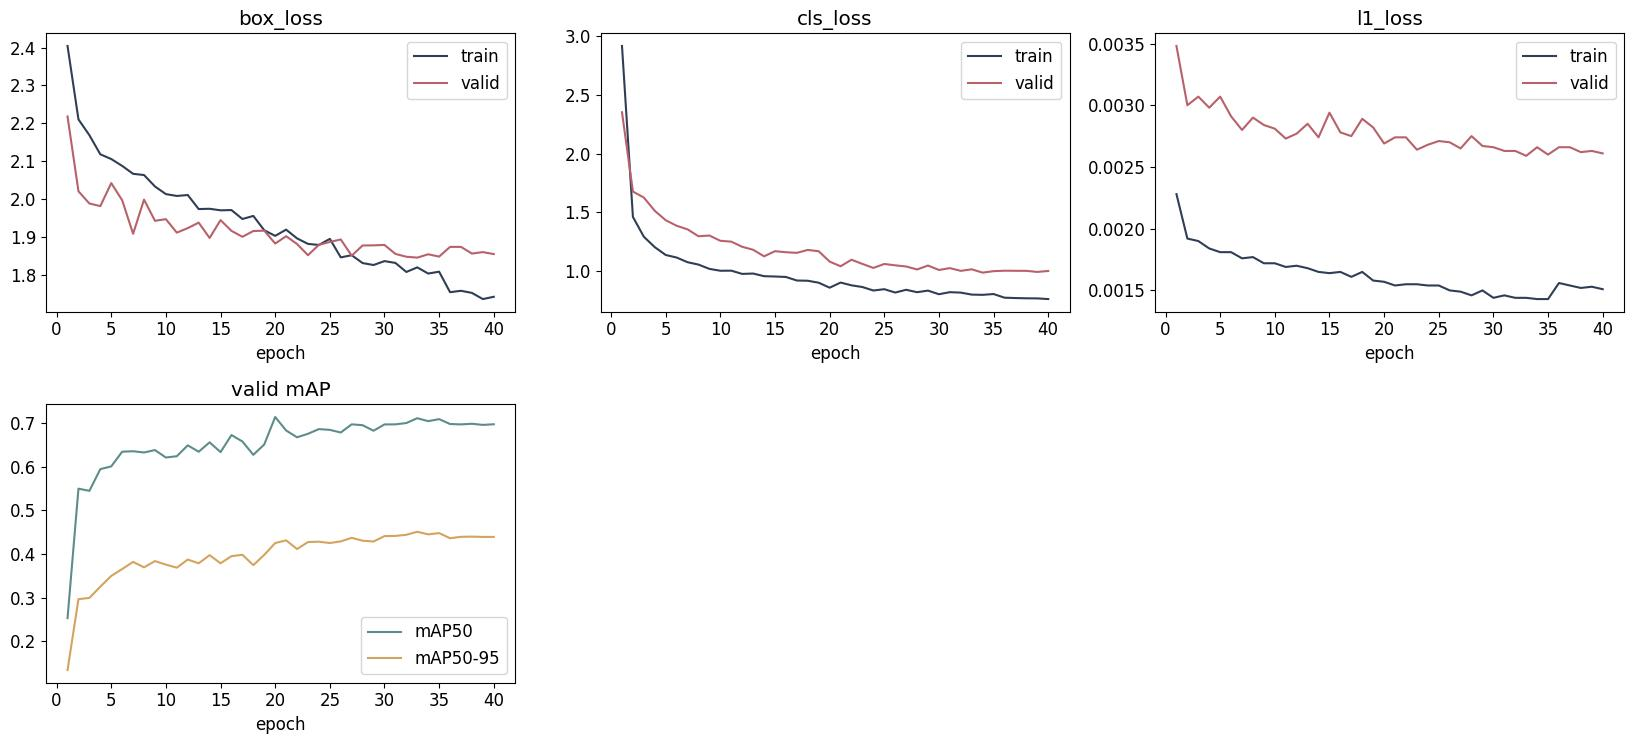

train time: 2001 s on Tesla T4
best epoch by valid mAP50-95: 33 of 40
valid mAP50 at the last epoch: 0.6972, at the best: 0.7110


In [22]:
results = read_results(run_dir)
epochs = results['epoch']
components = [key.split('/', 1)[1] for key in results if key.startswith('train/')]

n_panels = len(components) + 1
n_columns = 3
n_rows = math.ceil(n_panels / n_columns)
fig, axes = plt.subplots(n_rows, n_columns, figsize=(5.5 * n_columns, 3.8 * n_rows))
axes = np.atleast_1d(axes).ravel()

for ax, component in zip(axes, components):
    ax.plot(epochs, results[f'train/{component}'], color=COLORS[0], label='train')
    if f'val/{component}' in results:
        ax.plot(epochs, results[f'val/{component}'], color=COLORS[1], label='valid')
    ax.set_title(component)
    ax.set_xlabel('epoch')
    ax.legend()

metric_ax = axes[len(components)]
metric_ax.plot(epochs, results['metrics/mAP50(B)'], color=COLORS[2], label='mAP50')
metric_ax.plot(epochs, results['metrics/mAP50-95(B)'], color=COLORS[3], label='mAP50-95')
metric_ax.set_title('valid mAP')
metric_ax.set_xlabel('epoch')
metric_ax.legend()

for ax in axes[n_panels:]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

best_epoch = int(np.argmax(results['metrics/mAP50-95(B)']))
print(f'train time: {RUN_TIMES["train"]:.0f} s on {DEVICE_NAME}')
print(f'best epoch by valid mAP50-95: {int(epochs[best_epoch])} of {int(epochs[-1])}')
print(f'valid mAP50 at the last epoch: {results["metrics/mAP50(B)"][-1]:.4f}, at the best: {results["metrics/mAP50(B)"][best_epoch]:.4f}')

**Ответ:** Размер входа 960, потому что объекты мелкие, а на 640 они сильно теряются. AdamW с косинусным lr задан явно, чтобы не зависеть от выбора `optimizer='auto'` в конкретной версии ultralytics. Из аугментаций включены flip по обеим осям (у съёмки сверху нет «верха») и мозаику, которая выключается на последних пяти эпохах.

По кривым: train loss падает всё время, valid loss к 30-й эпохе выходит на плато и в самом конце чуть растёт, так что слабое переобучение под конец есть, но сильного нет. Эпох хватило: лучшей оказалась 33-я из 40, early stopping не срабатывал. В начале valid loss ниже train, потому что на train включены сильные аугментации.

## 4.2 Метрики (3 балла)

Посчитайте метрики лучших весов (`best.pt`) через `model.val` на val и, если есть, на test: mAP50, mAP50-95, precision и recall в целом и по классам, PR-кривая и confusion matrix (картинки, которые ultralytics сохраняет в каталог валидации, можно показать через `plt.imread`). Заполните `FINAL` в формате ниже на `FINAL_SPLIT` (тот же сплит, что у бейзлайна в 3.1). Для сверки посчитайте mAP50 по предсказаниям `predict_records` функцией `evaluate_map50`.

**Вопрос.** Какие классы даются хуже и почему (размер, число примеров, похожесть на другие классы)? Что показывает confusion matrix, в частности строка и столбец background? Почему mAP50-95 сильно ниже mAP50? Насколько ваш mAP50 совпал с ultralytics и почему может не совпадать?

In [23]:
best = YOLO(run_dir / 'weights' / 'best.pt')


def val_metrics(model, split, name, **kw):
    return model.val(data=str(DATA_YAML), split=split, imgsz=IMGSZ, batch=BATCH, device=DEVICE, workers=WORKERS,
                     project=str(RUNS.resolve()), name=name, exist_ok=True, verbose=False, **kw)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO26n summary (fused): 121 layers, 2,390,707 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4127.5±629.7 MB/s, size: 226.2 KB)
val: Scanning /kaggle/working/data/yolo/labels/val.cache... 400 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 400/400 129.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 25/25 5.0it/s 5.0s
                   all        400       2931      0.767      0.707      0.713      0.453
Speed: 1.3ms preprocess, 6.1ms inference, 0.0ms loss, 0.8ms postprocess per image
Results saved to /kaggle/working/runs_hw2/val_final
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO26n summary (fused): 121 layers, 2,390,707 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3948.0±658.2 MB/s, size: 259.0 KB)
val: S

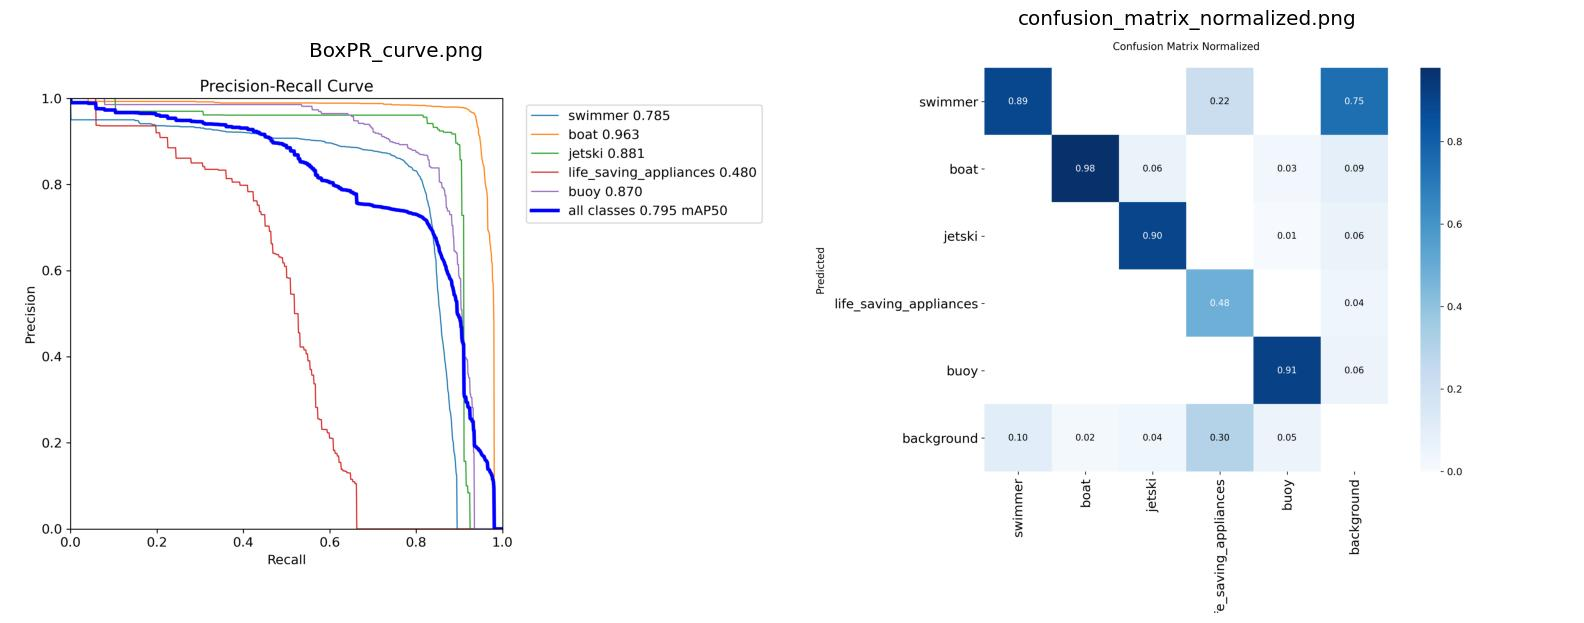

In [ ]:
def collect_metrics(metrics, split):
    # результат model.val -> словарь с общими и поклассовыми метриками (классы без разметки в сплите пропускаются)
    box = metrics.box
    n_instances = np.bincount(np.concatenate([record['labels'] for record in records[split]]), minlength=len(CLASSES))
    per_class = {}

    for position, class_index in enumerate(box.ap_class_index):
        precision, recall, ap50, ap50_95 = box.class_result(position)
        per_class[CLASSES[int(class_index)]] = dict(
            n_instances=int(n_instances[int(class_index)]),
            precision=float(precision),
            recall=float(recall),
            ap50=float(ap50),
            ap50_95=float(ap50_95),
        )

    return dict(
        split=split,
        map50=float(box.map50),
        map50_95=float(box.map),
        precision=float(box.mp),
        recall=float(box.mr),
        per_class=per_class,
    )


metrics_valid = val_metrics(best, 'val', 'val_final')
metrics_test = val_metrics(best, 'test', 'test_final') if 'test' in records else None

FINAL = collect_metrics(metrics_test if FINAL_SPLIT == 'test' else metrics_valid, FINAL_SPLIT)
FINAL['valid'] = collect_metrics(metrics_valid, 'val')

# сверка со своей функцией
own_preds = predict_records(best, records[FINAL_SPLIT])
FINAL['own_map50'], own_aps = evaluate_map50(own_preds, records[FINAL_SPLIT], len(CLASSES))

for split_name, summary in (('valid', FINAL['valid']), (FINAL_SPLIT, FINAL)):
    print(
        f'{split_name}: mAP50 {summary["map50"]:.4f}, mAP50-95 {summary["map50_95"]:.4f}, '
        f'P {summary["precision"]:.4f}, R {summary["recall"]:.4f}'
    )
    for name, values in summary['per_class'].items():
        print(
            f'  {name:<24} n={values["n_instances"]:>5}  P {values["precision"]:.3f}  R {values["recall"]:.3f}  '
            f'AP50 {values["ap50"]:.3f}  AP50-95 {values["ap50_95"]:.3f}'
        )

print(f'own mAP50 on {FINAL_SPLIT}: {FINAL["own_map50"]:.4f} (ultralytics: {FINAL["map50"]:.4f})')

# PR-кривая и confusion matrix, которые ultralytics сохранил при валидации на FINAL_SPLIT
save_dir = Path((metrics_test if FINAL_SPLIT == 'test' else metrics_valid).save_dir)
curve_path = sorted(save_dir.glob('*PR_curve.png'))[0]
matrix_path = save_dir / 'confusion_matrix_normalized.png'
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, path in zip(axes, (curve_path, matrix_path)):
    ax.imshow(plt.imread(path))
    ax.set_title(path.name)
    ax.set_axis_off()
    
plt.tight_layout()
plt.show()

In [25]:
assert 'FINAL' in globals(), 'сначала заполните FINAL в ячейке выше'
assert {'map50', 'map50_95', 'precision', 'recall', 'per_class'} <= set(FINAL)
assert 0 <= FINAL['map50_95'] <= FINAL['map50'] <= 1
{k: (round(v, 4) if isinstance(v, float) else v) for k, v in FINAL.items() if k != 'per_class'}

{'split': 'test',
 'map50': 0.7955,
 'map50_95': 0.4461,
 'precision': 0.8438,
 'recall': 0.7748,
 'valid': {'split': 'val',
  'map50': 0.7125348763291363,
  'map50_95': 0.4527200682663778,
  'precision': 0.7665645948064533,
  'recall': 0.7070518806082757,
  'per_class': {'swimmer': {'n_instances': 2146,
    'precision': 0.6593258277609189,
    'recall': 0.7320596458527493,
    'ap50': 0.6203288431346596,
    'ap50_95': 0.21467263411702064},
   'boat': {'n_instances': 245,
    'precision': 0.8554980622534305,
    'recall': 0.9142857142857143,
    'ap50': 0.929358771737172,
    'ap50_95': 0.6857569315232147},
   'jetski': {'n_instances': 178,
    'precision': 0.7694490130808409,
    'recall': 0.8314606741573034,
    'ap50': 0.8948232833288049,
    'ap50_95': 0.6721223076823905},
   'life_saving_appliances': {'n_instances': 179,
    'precision': 0.6393893888857931,
    'recall': 0.12849162011173185,
    'ap50': 0.23751903537591768,
    'ap50_95': 0.08153517323389889},
   'buoy': {'n_inst

**Ответ:** Хуже всего даётся `life_saving_appliances`: примеров в train очень мало, объекты крошечные, и модель путает их с пловцами (по confusion matrix часть таких объектов принимается за swimmer, а часть вообще пропускается). У пловцов mAP50 неплохой, но рамки получаются неточными, поэтому их mAP50-95 низкий. Лодки, гидроциклы и буи находятся уверенно. Почти все ложные срабатывания в строке и столбце background — это пловцы, то есть блики и волны на воде.

mAP50-95 намного ниже mAP50 (0.45 против 0.80), потому что усредняется по более строгим порогам IoU, а у объекта в десять пикселей сдвиг рамки на пиксель-два уже сильно роняет IoU. Собственный mAP50 вышел чуть ниже, чем у ultralytics, вероятно из-за деталей реализации

---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

mAP одним числом не говорит, что именно не так. Разложите ошибки модели на val по категориям своим кодом:

1. `box_iou_np(a, b)` - матрица IoU `(n, m)` для боксов xyxy на numpy
2. `categorize_predictions(pred, gt)` - категория для каждого предсказания одной картинки и список пропущенных объектов. Предсказания обходятся по убыванию score:
   - `'tp'` - тот же класс и IoU >= 0.5 с еще не найденным gt (этот gt становится найденным, берется gt с максимальным IoU)
   - иначе `'class'` (ошибка класса) - IoU >= 0.5 с gt другого класса
   - иначе `'localization'` (ошибка локализации) - тот же класс и IoU в [0.1, 0.5) с еще не найденным gt
   - иначе `'background'` (лишний бокс) - фон или дубль уже найденного объекта
   - `missed` (пропуск) - индексы gt, которые не стали tp и к которым не привязана ошибка класса или локализации (привязывается gt с максимальным IoU)
3. Посчитайте категории на val при `conf >= CONF_ERRORS`, доли и разбивку по классам, заполните `ERRORS = {категория: число}`. Покажите глазами 5+ примеров ошибок разных категорий: разметка и предсказания на одной картинке

**Вопрос.** Какая категория ошибок главная? Это ошибки модели или разметки (посмотрите на примеры)? Что бы вы сделали, чтобы уменьшить главную категорию?

In [ ]:
CONF_ERRORS = 0.001 if FAST_MODE else 0.25
ERROR_TYPES = ('tp', 'class', 'localization', 'background', 'missed')


def box_iou_np(a, b):
    # a: (n, 4), b: (m, 4) xyxy -> IoU (n, m); пустые входы -> массив формы (n, m)
    a = np.asarray(a, dtype=np.float64).reshape(-1, 4)
    b = np.asarray(b, dtype=np.float64).reshape(-1, 4)
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)))

    top_left = np.maximum(a[:, None, :2], b[None, :, :2])
    bottom_right = np.minimum(a[:, None, 2:], b[None, :, 2:])
    intersection = np.clip(bottom_right - top_left, 0, None).prod(axis=2)

    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1])
    area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    union = area_a[:, None] + area_b[None, :] - intersection

    return np.where(union > 0, intersection / np.maximum(union, 1e-12), 0.0)


def categorize_predictions(pred, gt, iou_hit=0.5, iou_loc=0.1):
    # pred: dict(boxes, scores, labels), gt: dict(boxes, labels) одной картинки
    # -> (список категорий предсказаний в исходном порядке, список индексов пропущенных gt)
    pred_boxes = np.asarray(pred['boxes'], dtype=np.float64).reshape(-1, 4)
    pred_labels = np.asarray(pred['labels']).reshape(-1)
    scores = np.asarray(pred['scores']).reshape(-1)
    gt_labels = np.asarray(gt['labels']).reshape(-1)

    ious = box_iou_np(pred_boxes, gt['boxes'])
    found = np.zeros(len(gt_labels), dtype=bool)
    attached = np.zeros(len(gt_labels), dtype=bool)
    categories = ['background'] * len(pred_boxes)

    if len(gt_labels):
        for i in np.argsort(-scores, kind='stable'):
            row = ious[i]
            same_class = gt_labels == pred_labels[i]

            # tp: тот же класс, IoU >= iou_hit с еще не найденным gt, берем gt с максимальным IoU
            candidates = np.where(same_class & ~found & (row >= iou_hit), row, -1.0)
            if candidates.max() >= iou_hit:
                found[candidates.argmax()] = True
                categories[i] = 'tp'
                continue

            # ошибка класса: IoU >= iou_hit с gt другого класса
            candidates = np.where(~same_class & (row >= iou_hit), row, -1.0)
            if candidates.max() >= iou_hit:
                attached[candidates.argmax()] = True
                categories[i] = 'class'
                continue

            # ошибка локализации: тот же класс, IoU в [iou_loc, iou_hit) с еще не найденным gt
            candidates = np.where(same_class & ~found & (row >= iou_loc) & (row < iou_hit), row, -1.0)
            if candidates.max() >= iou_loc:
                attached[candidates.argmax()] = True
                categories[i] = 'localization'

    missed = [index for index in range(len(gt_labels)) if not found[index] and not attached[index]]
    return categories, missed

In [27]:
rng = np.random.default_rng(0)
a, b = rng.uniform(0, 50, (7, 2)), rng.uniform(0, 50, (5, 2))
a, b = np.concatenate([a, a + rng.uniform(1, 30, (7, 2))], 1), np.concatenate([b, b + rng.uniform(1, 30, (5, 2))], 1)
assert np.allclose(box_iou_np(a, b), box_iou(torch.tensor(a), torch.tensor(b)).numpy(), atol=1e-6)
assert box_iou_np(np.zeros((0, 4)), b).shape == (0, 5) and box_iou_np(a, np.zeros((0, 4))).shape == (7, 0)

gt = dict(boxes=np.array([[0, 0, 10, 10], [20, 20, 30, 30], [50, 50, 60, 60], [80, 80, 90, 90]], dtype=float),
          labels=np.array([0, 0, 1, 1]))
pred = dict(boxes=np.array([[0, 0, 10, 10],          # tp: gt 0
                            [0, 0, 10, 10.5],        # дубль gt 0 -> background
                            [20, 20, 26, 26],        # IoU 0.36 с gt 1 -> localization
                            [50, 50, 60, 60],        # класс 0 на gt 2 класса 1 -> class
                            [100, 100, 110, 110]],   # фон -> background
                           dtype=float),
            scores=np.array([0.9, 0.8, 0.7, 0.6, 0.5]), labels=np.array([0, 0, 0, 0, 1]))
cats, missed = categorize_predictions(pred, gt)
assert list(cats) == ['tp', 'background', 'localization', 'class', 'background'], cats
assert list(missed) == [3], missed

pred2 = dict(boxes=np.array([[0, 0, 10, 10], [1, 0, 10, 10]], dtype=float), scores=np.array([0.3, 0.9]), labels=np.array([0, 0]))
cats, missed = categorize_predictions(pred2, dict(boxes=gt['boxes'][:1], labels=gt['labels'][:1]))
assert list(cats) == ['background', 'tp'] and list(missed) == [], (cats, missed)   # порядок по score, а не по списку

empty = dict(boxes=np.zeros((0, 4)), scores=np.zeros(0), labels=np.zeros(0, dtype=np.int64))
cats, missed = categorize_predictions(empty, gt)
assert list(cats) == [] and list(missed) == [0, 1, 2, 3]
cats, missed = categorize_predictions(pred, dict(boxes=np.zeros((0, 4)), labels=np.zeros(0, dtype=np.int64)))
assert list(cats) == ['background'] * 5 and list(missed) == []
print('box_iou_np / categorize_predictions: ok')

box_iou_np / categorize_predictions: ok


valid, conf >= 0.25: 400 images, 2931 objects
tp                2139   67.7%
class              100    3.2%
localization       498   15.8%
background         178    5.6%
missed             244    7.7%

class                               tp         class  localization    background        missed
swimmer                           1566            71           465           137           131
boat                               225             7            13            19             5
jetski                             151            21             4            10            22
life_saving_appliances              26             0             8             5            82
buoy                               171             1             8             7             4


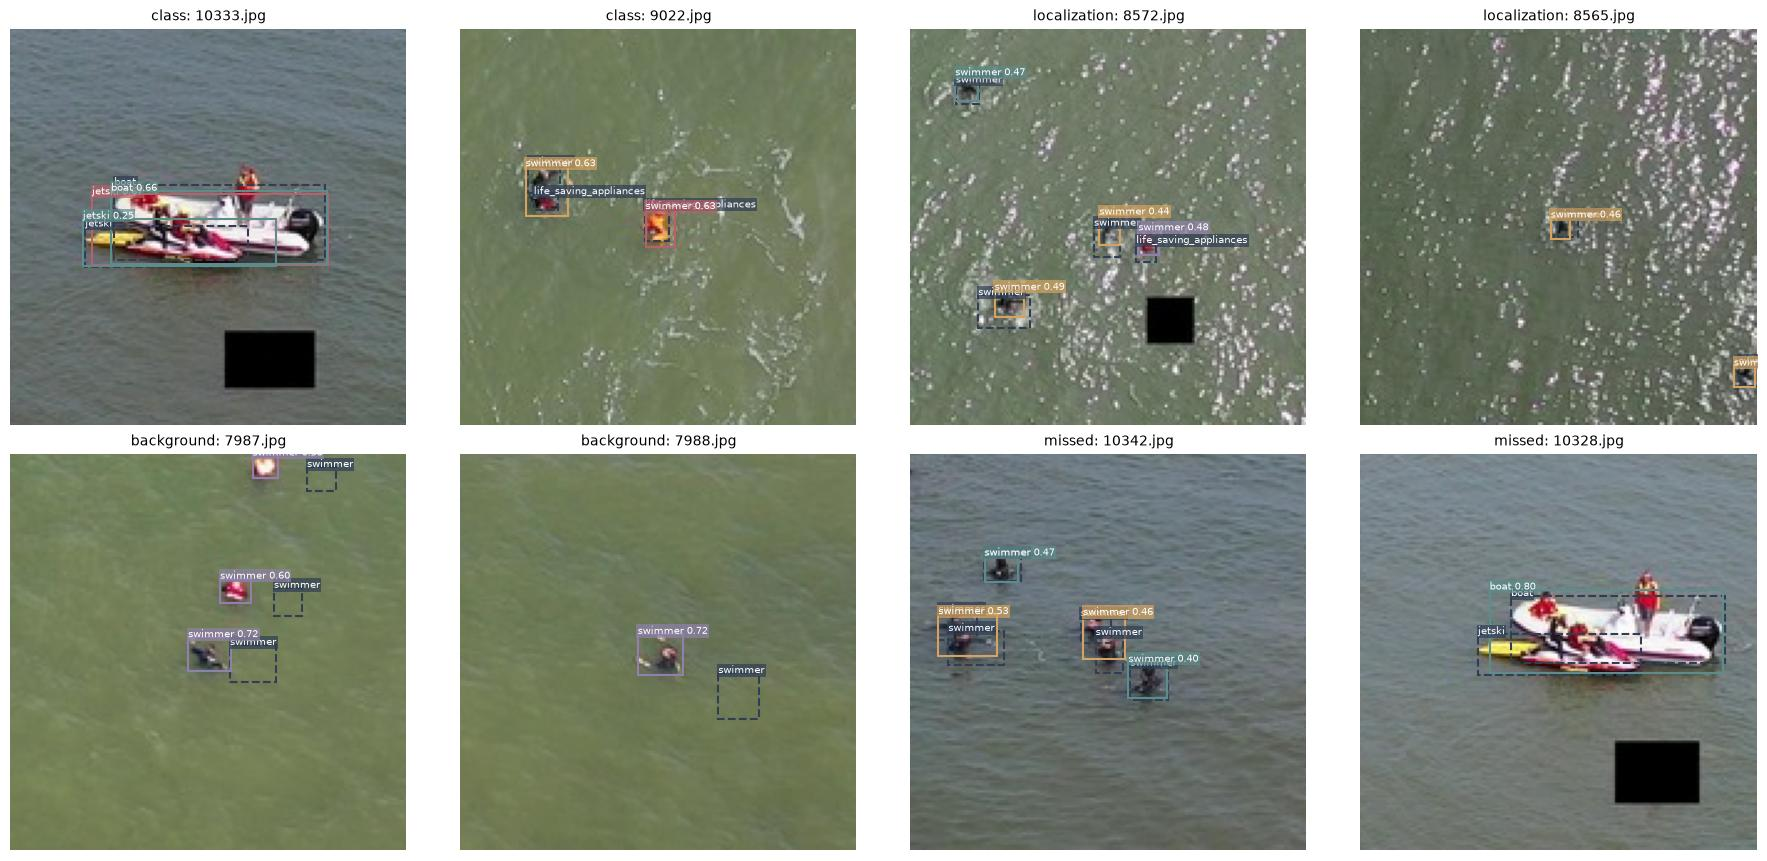

In [ ]:
valid_preds = predict_records(best, records['val'], conf=CONF_ERRORS)

error_counts = Counter()
class_breakdown = {category: Counter() for category in ERROR_TYPES}
analysis = []

for record, pred in zip(records['val'], valid_preds):
    categories, missed = categorize_predictions(pred, record)
    analysis.append((categories, missed))

    for label, category in zip(pred['labels'], categories):
        error_counts[category] += 1
        class_breakdown[category][CLASSES[int(label)]] += 1

    error_counts['missed'] += len(missed)
    for index in missed:
        class_breakdown['missed'][CLASSES[int(record['labels'][index])]] += 1

ERRORS = {category: error_counts[category] for category in ERROR_TYPES}
total_items = sum(ERRORS.values())

print(f'valid, conf >= {CONF_ERRORS}: {len(records["val"])} images, {sum(len(record["labels"]) for record in records["val"])} objects')
for category, count in ERRORS.items():
    print(f'{category:<14} {count:>7}  {count / total_items:>6.1%}')

print()
print(f'{"class":<24}' + ''.join(f'{category:>14}' for category in ERROR_TYPES))
for name in CLASSES:
    print(f'{name:<24}' + ''.join(f'{class_breakdown[category][name]:>14}' for category in ERROR_TYPES))

# примеры ошибок: окно 160x160 вокруг ошибки
# штрихованная линия - разметка, сплошная - предсказания, цвет - категория
CATEGORY_COLORS = {
    'tp': COLORS[2],
    'class': COLORS[1],
    'localization': COLORS[3],
    'background': COLORS[4],
}

examples = {kind: [] for kind in ('class', 'localization', 'background', 'missed')}
for image_index, (categories, missed) in enumerate(analysis):
    for item_index, category in enumerate(categories):
        if category in examples:
            examples[category].append((image_index, item_index))
    for item_index in missed:
        examples['missed'].append((image_index, item_index))

example_rng = np.random.default_rng(SEED)
chosen = []
for kind, items in examples.items():
    for pick in example_rng.choice(len(items), min(2, len(items)), replace=False) if items else []:
        chosen.append((kind, items[pick]))

HALF = 80
fig, axes = plt.subplots(2, 4, figsize=(18, 8.5), constrained_layout=True)

for ax, (kind, (image_index, item_index)) in zip(axes.ravel(), chosen):
    record, pred, categories = records['val'][image_index], valid_preds[image_index], analysis[image_index][0]
    box = record['boxes'][item_index] if kind == 'missed' else pred['boxes'][item_index]
    x0 = int(np.clip((box[0] + box[2]) / 2 - HALF, 0, max(record['width'] - 2 * HALF, 0)))
    y0 = int(np.clip((box[1] + box[3]) / 2 - HALF, 0, max(record['height'] - 2 * HALF, 0)))
    x1, y1 = min(x0 + 2 * HALF, record['width']), min(y0 + 2 * HALF, record['height'])
    offset = np.array([x0, y0, x0, y0])

    def inside_window(boxes):
        centers = (boxes[:, :2] + boxes[:, 2:]) / 2 - offset[:2]
        return (centers >= 0).all(axis=1) & (centers[:, 0] < x1 - x0) & (centers[:, 1] < y1 - y0)

    gt_inside = inside_window(record['boxes'])
    draw_boxes(
        ax,
        np.asarray(Image.open(record['image']).convert('RGB'))[y0:y1, x0:x1],
        record['boxes'][gt_inside] - offset,
        record['labels'][gt_inside],
        CLASSES,
        color=COLORS[0],
        linestyle='--',
    )

    pred_inside = inside_window(pred['boxes'])
    for category in set(categories):
        selection = np.array([item == category for item in categories]) & pred_inside
        draw_boxes(
            ax,
            None,
            pred['boxes'][selection] - offset,
            pred['labels'][selection],
            CLASSES,
            scores=pred['scores'][selection],
            color=CATEGORY_COLORS[category],
        )
        
    ax.set_xlim(0, x1 - x0)
    ax.set_ylim(y1 - y0, 0)
    for text in ax.texts:
        text.set_clip_on(True)
    ax.set_title(f'{kind}: {Path(record["image"]).name}', fontsize=10)

for ax in axes.ravel()[len(chosen):]:
    ax.set_visible(False)

plt.show()

**Ответ:** Главная категория ошибок — локализация (около 500 случаев, остальные категории заметно меньше), и почти все они приходятся на пловцов. Это ошибки границы бокса, а не поиска объекта. По примерам видно, что часть косяков — это шум разметки. Ошибки класса возникают на перекрывающихся объектах (лодка и гидроцикл на левом верхнем кадре) и на похожих пловцах и спасательных средствах. Чтобы уменьшить главную категорию, стоит поднять разрешение или считать по тайлам, чтобы рамки у мелких объектов были точнее, и отдельно проверить разметку со смещёнными рамками.

## 5.2 Абляция (1 балл)

Одна абляция на ваш выбор, остальные гиперпараметры как в 4.1:

- `imgsz`: например 320 против 640 (особенно интересно для мелких объектов)
- заморозка backbone: аргумент `freeze=<число первых слоев>`, backbone - первые `len(arch.yaml['backbone'])` слоев
- размер модели: n против s

Заполните `ABLATION`: что меняли, значения, mAP50 / mAP50-95 на val для обоих вариантов, время обучения.

**Вопрос.** Что изменилось и почему? Стоит ли это изменение своей цены по времени и качеству?

In [ ]:
# абляция по размеру входа: уменьшенный imgsz против основного, остальные гиперпараметры из 4.1
ABLATION_IMGSZ = 160 if FAST_MODE else 640

model_ablation, RUN_TIMES['ablation'], ablation_dir = train_yolo('ablation_imgsz', **{**TRAIN_ARGS, 'imgsz': ABLATION_IMGSZ})
print(f'ablation training: {RUN_TIMES["ablation"]:.0f} s on {DEVICE_NAME}, imgsz {ABLATION_IMGSZ}')

ablation_best = YOLO(ablation_dir / 'weights' / 'best.pt')
metrics_ablation = ablation_best.val(
    data=str(DATA_YAML),
    split='val',
    imgsz=ABLATION_IMGSZ,
    batch=BATCH,
    device=DEVICE,
    workers=WORKERS,
    project=str(RUNS.resolve()),
    name='val_ablation',
    exist_ok=True,
    verbose=False,
)
ablation_summary = collect_metrics(metrics_ablation, 'val')

ABLATION = dict(
    change='imgsz',
    values=[ABLATION_IMGSZ, IMGSZ],
    split='val',
    map50=[ablation_summary['map50'], FINAL['valid']['map50']],
    map50_95=[ablation_summary['map50_95'], FINAL['valid']['map50_95']],
    train_seconds=[RUN_TIMES['ablation'], RUN_TIMES['train']],
    ap50_per_class=dict(
        zip(
            [ABLATION_IMGSZ, IMGSZ],
            [
                {name: values['ap50'] for name, values in ablation_summary['per_class'].items()},
                {name: values['ap50'] for name, values in FINAL['valid']['per_class'].items()},
            ],
        )
    ),
)

print(f'{"imgsz":>6} {"mAP50":>8} {"mAP50-95":>9} {"train, s":>9}')
for index, imgsz in enumerate(ABLATION['values']):
    print(f'{imgsz:>6} {ABLATION["map50"][index]:>8.4f} {ABLATION["map50_95"][index]:>9.4f} {ABLATION["train_seconds"][index]:>9.0f}')

print()
print('AP50 per class (valid):')

for name in CLASSES:
    values = [ABLATION['ap50_per_class'][imgsz].get(name, float('nan')) for imgsz in ABLATION['values']]
    print(f'  {name:<24}' + ''.join(f'{value:>9.3f}' for value in values))

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=5, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=data/yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=ablation_imgsz, nbs=64, nms=None, opset=None, optimize=False, optimize

**Ответ:** Сравнивались размеры входа 640 и 960, остальное одинаково. С 960 качество заметно лучше: mAP50 на valid вырос с 0.65 до 0.71, mAP50-95 с 0.38 до 0.45. Сильнее всего выиграли самые мелкие классы (спасательные средства, гидроциклы), у крупных лодок разница небольшая. Причина в размере объектов: на 640 пловец занимает около семи пикселей, и самая подробная карта признаков их почти не различает. Цена — обучение занимает вдвое больше времени, а картинка обрабатывается чуть медленнее, но для заметного выигрыша это приемлемо.

## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, ограничения эксперимента (размер val, один seed, качество разметки), что бы сделали дальше.

**Ответ:**
- Дообучение YOLO26n заметно улучшило всё относительно бейзлайнов: mAP50 на test около 0.80 против 0.17 у COCO-модели и 0.02 у эвристики. Главным рычагом оказалось разрешение: переход с 640 на 960 дал около шести пунктов mAP50.
- Лодки, гидроциклы и буи детектируются хорошо, слабые места — спасательные средства (мало примеров, мелкие, похожи на пловцов) и точность рамок у пловцов.

Ограничения: один seed, valid небольшой и по составу классов отличается от test, а seed разбиения подбирался по разметке. Дальше стоит попробовать инференс по тайлам или размер больше, чаще показывать модели кадры с редким классом и добавить аугментации сжатием и шумом.

### Сохранение результатов обязательной части

Ячейка сохраняет `artifacts/metrics.json` (общий формат ДЗ2), `artifacts/results.csv` и `artifacts/best.pt`. Выполняется и в FAST_MODE для проверки формата; при окончательном прогоне файлы перезаписываются с `fast_mode: false`. Каталог `artifacts/` сдается вместе с ноутбуком.

In [30]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


artifact_dir = Path('artifacts')
artifact_dir.mkdir(exist_ok=True)
metrics = dict(
    track='cv', model=WEIGHTS,
    revision=f'ultralytics=={MODEL_INFO["ultralytics"]}; sha256={MODEL_INFO["sha256"]}',
    dataset=DATASET_NAME, classes=CLASSES,
    n_train=len(train_recs), n_val=len(records['val']), n_test=len(records['test']) if 'test' in records else None,
    params_total=int(sum(blocks.values())), baseline=BASELINE, final=FINAL, ablation=ABLATION, errors=ERRORS,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES['train'], fast_mode=FAST_MODE,
    train_args=TRAIN_ARGS, run_times=RUN_TIMES,
)
(artifact_dir / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2, allow_nan=False),
                                           encoding='utf-8')
shutil.copy(run_dir / 'results.csv', artifact_dir / 'results.csv')
shutil.copy(run_dir / 'weights' / 'best.pt', artifact_dir / 'best.pt')
print('Сохранено:', [p.name for p in sorted(artifact_dir.iterdir())])

Сохранено: ['best.pt', 'metrics.json', 'results.csv']


---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за все бонусы вместе - не больше 4 баллов. Сравнения делайте на том же val, что и в 4.2.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых картинок (CVAT, Label Studio или Roboflow Annotate, экспорт сразу в YOLO-формат), например из другого источника того же домена или из неразмеченной части датасета. Добавьте их в train, переобучите с теми же `TRAIN_ARGS` и сравните метрики на прежнем val. Опишите, сколько времени заняла разметка и какие были спорные случаи. Разметку положите в репозиторий (`extra/images`, `extra/labels`).

**Вопрос.** Как изменились метрики и стоило ли это потраченного времени?

In [31]:
if '6.1' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Ответ:** 

## 6.2 Другая архитектура: RT-DETR (1 балл)

Дообучите трансформерный детектор RT-DETR из ultralytics (`from ultralytics import RTDETR`, веса `rtdetr-l.pt`) на тех же данных и сравните с YOLO: mAP50, mAP50-95, число параметров, время обучения, задержка на картинку. RT-DETR тяжелее, при нехватке памяти уменьшите `batch`.

**Вопрос.** Что выиграли и что проиграли? Когда бы выбрали RT-DETR?

In [ ]:
if '6.2' in BONUS_TASKS:
    RTDETR_IMGSZ = ABLATION_IMGSZ
    RTDETR_EPOCHS = EPOCHS if FAST_MODE else min(EPOCHS, 15)
    RTDETR_BATCH = 4 if FAST_MODE else 8

    rtdetr = RTDETR('rtdetr-l.pt')
    start = time.perf_counter()
    rtdetr.train(
        data=str(DATA_YAML),
        device=DEVICE,
        workers=WORKERS,
        project=str(RUNS.resolve()),
        name='rtdetr',
        exist_ok=True,
        verbose=False,
        **{**TRAIN_ARGS, 'epochs': RTDETR_EPOCHS, 'imgsz': RTDETR_IMGSZ, 'batch': RTDETR_BATCH, 'lr0': 0.0001},
    )
    RUN_TIMES['rtdetr'] = time.perf_counter() - start

    rtdetr_best = RTDETR(Path(rtdetr.trainer.save_dir) / 'weights' / 'best.pt')
    rtdetr_params = sum(parameter.numel() for parameter in rtdetr_best.model.parameters())
    metrics_rtdetr = rtdetr_best.val(
        data=str(DATA_YAML),
        split='val',
        imgsz=RTDETR_IMGSZ,
        batch=RTDETR_BATCH,
        device=DEVICE,
        workers=WORKERS,
        project=str(RUNS.resolve()),
        name='val_rtdetr',
        exist_ok=True,
        verbose=False,
    )

    RTDETR_COMPARISON = {
        'yolo26n main': dict(
            imgsz=IMGSZ,
            epochs=EPOCHS,
            params=sum(blocks.values()),
            map50=FINAL['valid']['map50'],
            map50_95=FINAL['valid']['map50_95'],
            train_seconds=RUN_TIMES['train'],
            latency_ms=measure_latency(best, IMGSZ),
        ),
        'yolo26n ablation': dict(
            imgsz=ABLATION_IMGSZ,
            epochs=EPOCHS,
            params=sum(blocks.values()),
            map50=ABLATION['map50'][0],
            map50_95=ABLATION['map50_95'][0],
            train_seconds=RUN_TIMES['ablation'],
            latency_ms=measure_latency(ablation_best, ABLATION_IMGSZ),
        ),
        'rtdetr-l': dict(
            imgsz=RTDETR_IMGSZ,
            epochs=RTDETR_EPOCHS,
            params=rtdetr_params,
            map50=float(metrics_rtdetr.box.map50),
            map50_95=float(metrics_rtdetr.box.map),
            train_seconds=RUN_TIMES['rtdetr'],
            latency_ms=measure_latency(rtdetr_best, RTDETR_IMGSZ),
        ),
    }

    print(f'{"model":<18} {"imgsz":>6} {"epochs":>7} {"params, M":>10} {"mAP50":>7} {"mAP50-95":>9} {"train, s":>9} {"latency, ms":>12}')
    for name, row in RTDETR_COMPARISON.items():
        print(
            f'{name:<18} {row["imgsz"]:>6} {row["epochs"]:>7} {row["params"] / 1e6:>10.1f} {row["map50"]:>7.4f} '
            f'{row["map50_95"]:>9.4f} {row["train_seconds"]:>9.0f} {row["latency_ms"]:>12.1f}'
        )

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=5, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=data/yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.0001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=rtdetr-l.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=rtdetr, nbs=64, nms=None, opset=None, optimize=False, optimizer=AdamW

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


       1/15      6.51G      1.901     0.3836     0.2925         46        640: 100% ━━━━━━━━━━━━ 300/300 1.9it/s 2:35
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 25/25 2.8it/s 8.9s
                   all        400       2931      0.428       0.11     0.0312     0.0116

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
       2/15      6.99G      1.165      0.598      0.109         59        640: 0% ──────────── 0/300  0.5s

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


       2/15      6.99G      1.245     0.5477     0.1208         60        640: 100% ━━━━━━━━━━━━ 300/300 2.0it/s 2:30
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 25/25 3.1it/s 8.1s
                   all        400       2931      0.431      0.141     0.0414     0.0131

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
       3/15      6.99G      1.268     0.4906     0.1063         66        640: 0% ──────────── 0/300  0.5s

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


... (21 outputs left out)

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      14/15      6.99G     0.7287     0.5805    0.04905         48        640: 100% ━━━━━━━━━━━━ 300/300 2.0it/s 2:31
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 25/25 3.0it/s 8.5s
                   all        400       2931      0.567      0.431      0.373      0.218

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
      15/15      6.99G     0.7315     0.5981    0.05029         64        640: 0% ──────────── 0/300  0.5s

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      15/15      6.99G     0.7306     0.5682    0.04857         37        640: 100% ━━━━━━━━━━━━ 300/300 2.0it/s 2:30
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 25/25 3.0it/s 8.5s
                   all        400       2931      0.568      0.431      0.379      0.221

15 epochs completed in 0.668 hours.
Optimizer stripped from /kaggle/working/runs_hw2/rtdetr/weights/last.pt, 66.2MB
Optimizer stripped from /kaggle/working/runs_hw2/rtdetr/weights/best.pt, 66.2MB

Validating /kaggle/working/runs_hw2/rtdetr/weights/best.pt...
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
rt-detr-l summary (fused): 315 layers, 31,994,015 parameters, 0 gradients, 105.4 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 25/25 2.6it/s 9.6s
                   all        400       2931      0.568      0.439      0.378       0.22
Speed: 0.2ms prepr

**Ответ:** При том же размере входа (640) RT-DETR-l заметно проигрывает: mAP50 около 0.38 против 0.65 у YOLO26n, при этом модель примерно в 13 раз больше и в 6-7 раз медленнее на одной картинке. Сравнение не прям честное, поскольку RT-DETR обучался 15 эпох вместо 40 из-за времени, а трансформерные детекторы обычно сходятся дольше. Но даже это не говорит ничего в пользу RT-DETR-l, слишком уж большая разница во времени работы и в размерах модели.

## 6.3 Устойчивость к сдвигу домена (1 балл)

Сделайте 2-3 искаженные копии val (затемнение, гауссов шум, сильное JPEG-сжатие или картинки из другого источника того же домена), разметка та же. Посчитайте mAP50 / mAP50-95 дообученной модели на каждой копии.

**Вопрос.** Какое искажение бьет сильнее всего и по каким классам? Какая аугментация при обучении могла бы помочь?

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO26n summary (fused): 121 layers, 2,390,707 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2483.4±565.5 MB/s, size: 109.9 KB)
val: Scanning /kaggle/working/data/shift/dark/labels/val... 400 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 400/400 1.2Kit/s 0.3s
val: New cache created: /kaggle/working/data/shift/dark/labels/val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 25/25 4.7it/s 5.3s
                   all        400       2931       0.75      0.646      0.667      0.416
Speed: 1.3ms preprocess, 6.1ms inference, 0.0ms loss, 1.0ms postprocess per image
Results saved to /kaggle/working/runs_hw2/shift_dark
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO26n summary (fused): 121 layers, 2,390,707 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image acc

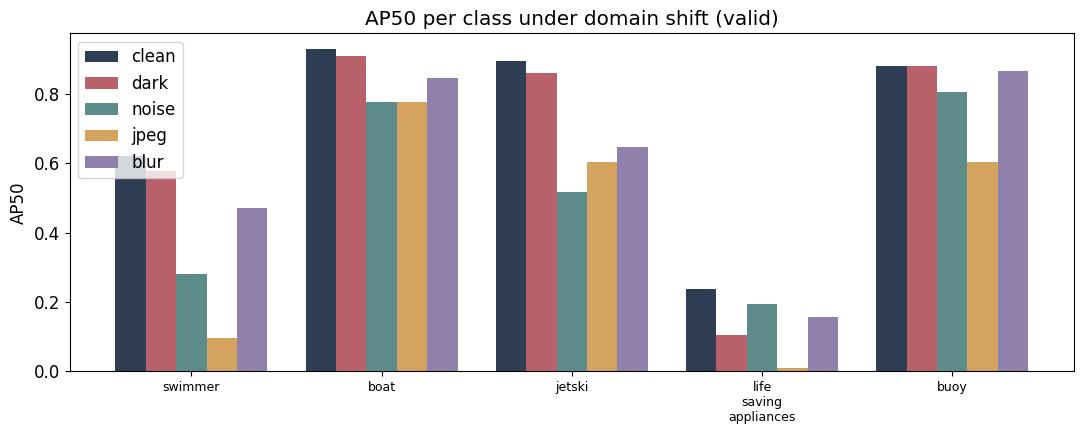

In [ ]:
if '6.3' in BONUS_TASKS:
    shift_rng = np.random.default_rng(SEED)

    def make_dark(image):
        return Image.fromarray((np.asarray(image, dtype=np.float32) * 0.3).astype(np.uint8))

    def make_noisy(image):
        noisy = np.asarray(image, dtype=np.float32) + shift_rng.normal(0, 25, (image.height, image.width, 3))
        return Image.fromarray(np.clip(noisy, 0, 255).astype(np.uint8))

    def make_compressed(image):
        buffer = io.BytesIO()
        image.save(buffer, format='JPEG', quality=5)
        return Image.open(io.BytesIO(buffer.getvalue())).convert('RGB')

    def make_blurred(image):
        return image.filter(ImageFilter.GaussianBlur(3))

    SHIFTS = {
        'dark': make_dark,
        'noise': make_noisy,
        'jpeg': make_compressed,
        'blur': make_blurred,
    }

    SHIFT_RESULTS = {
        'clean': dict(
            map50=FINAL['valid']['map50'],
            map50_95=FINAL['valid']['map50_95'],
            ap50_per_class={name: values['ap50'] for name, values in FINAL['valid']['per_class'].items()},
        ),
    }

    for shift_name, transform in SHIFTS.items():
        shift_root = DATA_ROOT / 'shift' / shift_name
        shutil.rmtree(shift_root, ignore_errors=True)
        (shift_root / 'images' / 'val').mkdir(parents=True)
        (shift_root / 'labels' / 'val').mkdir(parents=True)

        for record in records['val']:
            image_name = Path(record['image']).name
            transform(Image.open(record['image']).convert('RGB')).save(shift_root / 'images' / 'val' / image_name, quality=92)
            shutil.copy(YOLO_ROOT / 'labels' / 'val' / f'{Path(image_name).stem}.txt', shift_root / 'labels' / 'val')

        shift_yaml = shift_root / 'data.yaml'
        shift_yaml.write_text(
            f'path: {shift_root.resolve().as_posix()}\n'
            'train: images/val\n'
            'val: images/val\n'
            'names:\n' + ''.join(f'  {index}: {name}\n' for index, name in enumerate(CLASSES))
        )

        metrics_shift = best.val(
            data=str(shift_yaml),
            split='val',
            imgsz=IMGSZ,
            batch=BATCH,
            device=DEVICE,
            workers=WORKERS,
            project=str(RUNS.resolve()),
            name=f'shift_{shift_name}',
            exist_ok=True,
            verbose=False,
        )

        summary = collect_metrics(metrics_shift, 'val')
        SHIFT_RESULTS[shift_name] = dict(
            map50=summary['map50'],
            map50_95=summary['map50_95'],
            ap50_per_class={name: values['ap50'] for name, values in summary['per_class'].items()},
        )

    print(f'{"shift":<8} {"mAP50":>8} {"mAP50-95":>9}' + ''.join(f'{name[:12]:>14}' for name in CLASSES))
    for shift_name, result in SHIFT_RESULTS.items():
        print(
            f'{shift_name:<8} {result["map50"]:>8.4f} {result["map50_95"]:>9.4f}'
            + ''.join(f'{result["ap50_per_class"].get(name, float("nan")):>14.3f}' for name in CLASSES)
        )

    fig, ax = plt.subplots(figsize=(11, 4.5))
    bar_width = 0.8 / len(SHIFT_RESULTS)
    for position, (shift_name, result) in enumerate(SHIFT_RESULTS.items()):
        ax.bar(
            np.arange(len(CLASSES)) + position * bar_width,
            [result['ap50_per_class'].get(name, 0.0) for name in CLASSES],
            bar_width,
            label=shift_name,
            color=COLORS[position],
        )
    ax.set_xticks(np.arange(len(CLASSES)) + 0.4 - bar_width / 2, [name.replace('_', '\n') for name in CLASSES], fontsize=9)
    ax.set_ylabel('AP50')
    ax.set_title('AP50 per class under domain shift (valid)')
    ax.legend()
    
    plt.tight_layout()
    plt.show()

**Ответ:** Сильнее всего бьёт сильное JPEG-сжатие: mAP50 на valid падает с 0.71 до 0.42. Заметно хуже становится и с шумом и с размытием, а затемнение почти не мешает, вероятно потому, что яркость и так аугментируется при обучении. Больше всего страдают мелкие классы: пловцы при сжатии почти пропадают, а крупные лодки держатся заметно лучше. Объект в несколько пикселей держится на мелких деталях, а JPEG-блоки, шум и размытие стирают именно их. Помогли бы аугментации сжатием, шумом и размытием при обучении.

## 6.4 Экспорт и скорость (1 балл)

Экспортируйте дообученную модель в ONNX (`best.export(format='onnx', imgsz=IMGSZ)`; ultralytics сам доставит `onnx`, но надежнее `%pip install onnx onnxruntime`) или ускорьте ее иначе (TensorRT, half precision, квантизация). Сравните задержку на картинку до и после (прогрев, одинаковые условия, укажите устройство) и проверьте, что mAP50 не упал.

**Вопрос.** Во сколько раз ускорилось, за счет чего, и сколько стоило в качестве?

In [ ]:
if '6.4' in BONUS_TASKS:
    onnx_path = Path(best.export(format='onnx', imgsz=IMGSZ))
    onnx_model = YOLO(onnx_path, task='detect')
    print(f'exported: {onnx_path.name}, {onnx_path.stat().st_size / 2 ** 20:.1f} MB')

    configs = [
        ('pytorch fp32', best, 'cpu', {}),
        ('onnx fp32', onnx_model, 'cpu', {}),
    ]
    if torch.cuda.is_available():
        configs += [
            ('pytorch fp32', best, 0, {}),
            ('pytorch fp16', best, 0, dict(half=True)),
        ]

    SPEED_RESULTS = []
    for name, model, device, kwargs in configs:
        latency = measure_latency(model, IMGSZ, runs=10 if device == 'cpu' else 20, device=device, **kwargs)
        metrics_speed = model.val(
            data=str(DATA_YAML),
            split='val',
            imgsz=IMGSZ,
            batch=1 if name.startswith('onnx') else BATCH,
            device=device,
            workers=WORKERS,
            project=str(RUNS.resolve()),
            name='val_speed',
            exist_ok=True,
            verbose=False,
            **kwargs,
        )
        
        SPEED_RESULTS.append(dict(
            model=name,
            device='cpu' if device == 'cpu' else DEVICE_NAME,
            latency_ms=latency,
            map50=float(metrics_speed.box.map50),
            map50_95=float(metrics_speed.box.map),
        ))

    print(f'{"model":<14} {"device":<18} {"latency, ms":>12} {"mAP50":>8} {"mAP50-95":>9}')
    for row in SPEED_RESULTS:
        print(f'{row["model"]:<14} {row["device"]:<18} {row["latency_ms"]:>12.1f} {row["map50"]:>8.4f} {row["map50_95"]:>9.4f}')

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO26n summary (fused): 121 layers, 2,390,707 parameters, 0 gradients, 12.4 GFLOPs

PyTorch: starting from '/kaggle/working/runs_hw2/finetune/weights/best.pt' with input shape (1, 3, 960, 960) BCHW and output shape(s) (1, 9, 18900) (5.3 MB)
requirements: Ultralytics requirements ['onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 12 packages in 331ms
 Downloaded onnxruntime
Prepared 2 packages in 338ms
Installed 2 packages in 7ms
 + onnxruntime==1.32.0
 + onnxslim==0.1.99

requirements: AutoUpdate success ✅ 1.0s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: slimming with onnxslim 0.1.99...
ONNX:

**Ответ:** ONNX на CPU ускорил инференс примерно в 1.4 раза без заметной потери качества: граф перед выполнением оптимизируется, и исполнитель легче, чем PyTorch на CPU. FP16 на T4 дал совсем немного (около 10%) при потере в десятые доли пункта mAP50: модель маленькая, и время на GPU уходит больше на накладные расходы, чем на сами вычисления.

## 6.5 Пороги (1 балл)

Посмотрите, как порог уверенности `conf` и порог IoU в NMS (`iou`) меняют precision, recall и mAP на val (сетка хотя бы 4 x 2). Учтите, что YOLO26 по умолчанию работает end-to-end без NMS: проверьте, влияет ли `iou` вообще, и сравните с `end2end=False` (ветка one2many + NMS).

**Вопрос.** Какой `conf` вы бы выбрали для своей задачи и почему? Почему mAP почти не зависит от `conf`, а P и R зависят сильно? Влияет ли `iou` в end-to-end режиме?

WARNING ⚠️ 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO26n summary (fused): 122 layers, 2,390,707 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2269.1±825.4 MB/s, size: 245.7 KB)
val: Scanning /kaggle/working/data/yolo/labels/val.cache... 400 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 400/400 129.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 25/25 5.8it/s 4.3s
                   all        400       2931      0.782      0.679       0.71      0.435
Speed: 1.1ms preprocess, 6.3ms inference, 0.0ms loss, 0.1ms postprocess per image
WARNING ⚠️ 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO26n summary (fused): 1

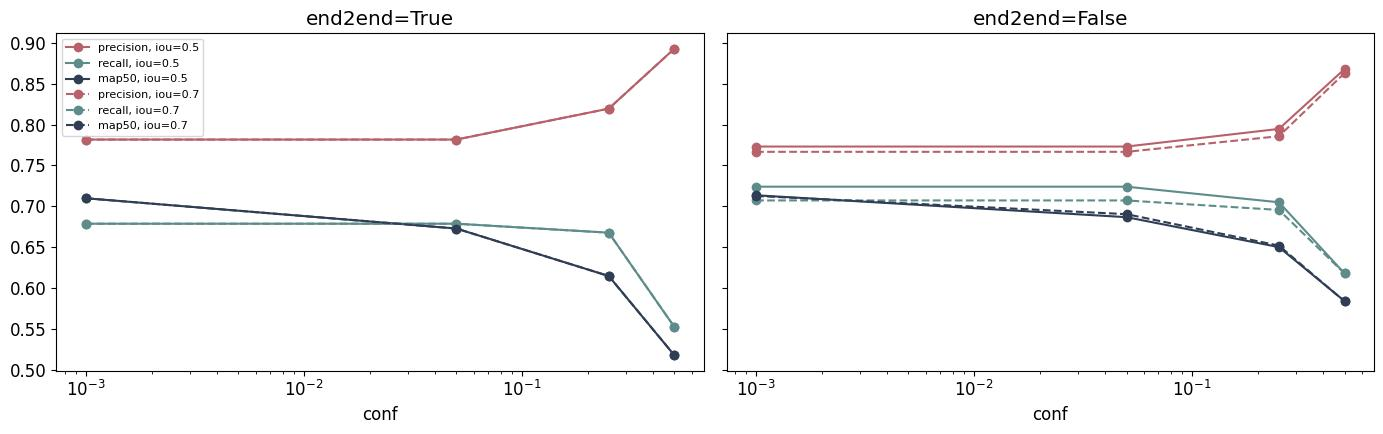

In [ ]:
if '6.5' in BONUS_TASKS:
    CONFS = [0.001, 0.05, 0.25, 0.5]
    IOUS = [0.5, 0.7]

    THRESHOLD_RESULTS = []
    for end2end in (True, False):
        for conf in CONFS:
            for iou in IOUS:
                metrics_threshold = best.val(
                    data=str(DATA_YAML),
                    split='val',
                    imgsz=IMGSZ,
                    batch=BATCH,
                    conf=conf,
                    iou=iou,
                    end2end=end2end,
                    device=DEVICE,
                    workers=WORKERS,
                    project=str(RUNS.resolve()),
                    name='val_thresholds',
                    exist_ok=True,
                    verbose=False,
                    plots=False,
                )

                THRESHOLD_RESULTS.append(dict(
                    end2end=end2end,
                    conf=conf,
                    iou=iou,
                    precision=float(metrics_threshold.box.mp),
                    recall=float(metrics_threshold.box.mr),
                    map50=float(metrics_threshold.box.map50),
                    map50_95=float(metrics_threshold.box.map),
                ))

    print(f'{"end2end":<8} {"conf":>6} {"iou":>5} {"P":>7} {"R":>7} {"mAP50":>7} {"mAP50-95":>9}')
    for row in THRESHOLD_RESULTS:
        print(
            f'{str(row["end2end"]):<8} {row["conf"]:>6} {row["iou"]:>5} {row["precision"]:>7.3f} '
            f'{row["recall"]:>7.3f} {row["map50"]:>7.3f} {row["map50_95"]:>9.3f}'
        )

    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
    for ax, end2end in zip(axes, (True, False)):
        for iou, linestyle in zip(IOUS, ('-', '--')):
            rows = [row for row in THRESHOLD_RESULTS if row['end2end'] == end2end and row['iou'] == iou]
            for metric, color in (('precision', COLORS[1]), ('recall', COLORS[2]), ('map50', COLORS[0])):
                ax.plot(CONFS, [row[metric] for row in rows], linestyle, color=color, marker='o', label=f'{metric}, iou={iou}')
        ax.set_xscale('log')
        ax.set_xlabel('conf')
        ax.set_title(f'end2end={end2end}')
        
    axes[0].legend(fontsize=8)
    plt.tight_layout()
    plt.show()

**Ответ:** В режиме без NMS параметр `iou` ни на что не влияет (результаты для 0.5 и 0.7 совпадают, NMS там нет), а с NMS влияет слабо. От `conf` precision и recall зависят заметно: с ростом порога precision растёт, а recall падает. mAP на низких порогах почти не меняется, потому что порог лишь отрезает хвост PR-кривой с низкими score, и заметно падает только на высоких. Для поиска людей подошёл бы `conf` около 0.05: пропустить пловца хуже, чем получить лишнюю тревогу, а precision при этом падает совсем немного.